In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import seaborn as sns
from scipy.stats import norm
from IPython.display import display, HTML
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
%config InlineBackend.figure_format = "png2x"

In [2]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
COLORS = {
    "aqua": "#3EAFBD",
    "light_aqua": "#83D5DF",
    "pale_aqua": "#C5F0F0",
    "apricot": "#F6B477",
    "lavender": "#A8B6E5"
}

PALETTE = list(COLORS.values())

PRIMARY_COLOR = COLORS["aqua"]
SECONDARY_COLOR = COLORS["apricot"]
ACCENT_COLOR = COLORS["light_aqua"]
NEUTRAL_COLOR = COLORS["lavender"]

# Data Loading

In [4]:
spend = pd.read_pickle('/content/drive/MyDrive/Final_Project/spend_cleaned.pkl')
spend.head()

,Date,Source,Campaign,Impressions,Spend,Clicks,AdGroup,Ad
0,2023-07-03,Google Ads,gen_analyst_DE,6,0.00,0,NaN,NaN
1,2023-07-03,Google Ads,performancemax_eng_DE,4,0.01,1,NaN,NaN
2,2023-07-03,Facebook Ads,NaN,0,0.00,0,NaN,NaN
3,2023-07-03,Google Ads,NaN,0,0.00,0,NaN,NaN
4,2023-07-03,CRM,NaN,0,0.00,0,NaN,NaN


In [5]:
contacts = pd.read_pickle('/content/drive/MyDrive/Final_Project/contacts_cleaned.pkl')
contacts.head()

,Id,Contact Owner Name,Created Time,Modified Time
0,5805028000000645014,Rachel White,2023-06-27 11:28:00,2023-12-22 13:34:00
1,5805028000000872003,Charlie Davis,2023-07-03 11:31:00,2024-05-21 10:23:00
2,5805028000000889001,Bob Brown,2023-07-02 22:37:00,2023-12-21 13:17:00
3,5805028000000907006,Bob Brown,2023-07-03 05:44:00,2023-12-29 15:20:00
4,5805028000000939010,Nina Scott,2023-07-04 10:11:00,2024-04-16 16:14:00


In [6]:
calls = pd.read_pickle('/content/drive/MyDrive/Final_Project/calls_cleaned.pkl')
calls.head()

,Id,Call Start Time,Call Owner Name,CONTACTID,Call Type,Call Duration (in seconds),Call Status,Outgoing Call Status,Scheduled in CRM
0,5805028000000805001,2023-06-30 08:43:00,John Doe,NaN,Inbound,171.0,Received,NaN,NaN
1,5805028000000768006,2023-06-30 08:46:00,John Doe,NaN,Outbound,28.0,Attended Dialled,Completed,0.0
2,5805028000000764027,2023-06-30 08:59:00,John Doe,NaN,Outbound,24.0,Attended Dialled,Completed,0.0
3,5805028000000787003,2023-06-30 09:20:00,John Doe,5805028000000645014,Outbound,6.0,Attended Dialled,Completed,0.0
4,5805028000000768019,2023-06-30 09:30:00,John Doe,5805028000000645014,Outbound,11.0,Attended Dialled,Completed,0.0


In [7]:
deals = pd.read_pickle('/content/drive/MyDrive/Final_Project/deals_cleaned.pkl')

pd.set_option("display.max_columns", None)
deals.head()

,Id,Deal Owner Name,Closing Date,Quality,Stage,Lost Reason,Page,Campaign,Content,Term,Source,Payment Type,Product,Education Type,Created Time,Course duration,Months of study,Initial Amount Paid,Offer Total Amount,Contact Name,City,Level of Deutsch,Demo Access,SLA Seconds
0,5805028000056864695,Ben Hall,NaT,NaN,New Lead,NaN,/eng/test,03.07.23women,v16,women,Facebook Ads,NaN,NaN,NaN,2024-06-21 15:30:00,<NA>,<NA>,<NA>,<NA>,5805028000056849495,NaN,NaN,False,NaN
1,5805028000056859489,Ulysses Adams,NaT,NaN,New Lead,NaN,/at-eng,NaN,NaN,NaN,Organic,NaN,Web Developer,Morning,2024-06-21 15:23:00,6,<NA>,0,2000,5805028000056834471,NaN,NaN,True,NaN
2,5805028000056832357,Ulysses Adams,2024-06-21,D - Non Target,Lost,Non target,/at-eng,engwien_AT,b1-at,21_06_2024,Telegram posts,NaN,NaN,NaN,2024-06-21 14:45:00,<NA>,<NA>,<NA>,<NA>,5805028000056854421,NaN,NaN,False,1603.0
3,5805028000056824246,Eva Kent,2024-06-21,E - Non Qualified,Lost,Invalid number,/eng,04.07.23recentlymoved_DE,bloggersvideo14com,recentlymoved,Facebook Ads,NaN,NaN,NaN,2024-06-21 13:32:00,<NA>,<NA>,<NA>,<NA>,5805028000056889351,NaN,NaN,False,3604.0
4,5805028000056873292,Ben Hall,2024-06-21,D - Non Target,Lost,Non target,/eng,discovery_DE,website,NaN,Google Ads,NaN,NaN,NaN,2024-06-21 13:21:00,<NA>,<NA>,<NA>,<NA>,5805028000056876176,NaN,NaN,False,3192.0


# 1. Unit Economics

## Total Unit Economics

In [8]:
# UA — Potential Clients
UA_total = contacts["Id"].nunique()

In [9]:
# Paid non-demo deals
paid_deals = deals.loc[
    (deals["Stage"] == "Payment Done") &
    (~deals["Demo Access"])
].copy()

In [10]:
# B — Buyers
B_total = paid_deals["Contact Name"].nunique()

In [11]:
# Number of transactions per paid deal
paid_deals["n_transactions"] = 1.0

mask_installment = paid_deals["Payment Type"] != "One Payment"

paid_deals.loc[mask_installment, "n_transactions"] = (
    paid_deals.loc[mask_installment, "Months of study"]
    .clip(lower=1)
    .astype(float)
)

# Estimated regular payment
paid_deals["regular_payment"] = 0.0

paid_deals.loc[mask_installment, "regular_payment"] = (
    (
        paid_deals.loc[mask_installment, "Offer Total Amount"].astype(float)
        - paid_deals.loc[mask_installment, "Initial Amount Paid"].astype(float)
    )
    /
    (
        paid_deals.loc[mask_installment, "Course duration"].astype(float) - 1
    )
)

# Estimated revenue received to date
paid_deals["revenue"] = (
    paid_deals["Initial Amount Paid"].astype(float)
)

paid_deals.loc[mask_installment, "revenue"] = (
    paid_deals.loc[mask_installment, "Initial Amount Paid"].astype(float)
    + paid_deals.loc[mask_installment, "regular_payment"]
    * (paid_deals.loc[mask_installment, "n_transactions"] - 1)
)

# T — Transactions
T_total = paid_deals["n_transactions"].sum()

# Revenue
Revenue_total = paid_deals["revenue"].sum()

# AOV — Average Order Value
AOV_total = Revenue_total / T_total

Methodological Note: Paid Deals, Transactions and Revenue

Core unit economics includes only real paid non-demo deals (Stage = Payment Done, Demo Access = False). Since the dataset does not contain a transaction-level payment history, the number of transactions and revenue received to date are estimated from the available CRM data. One Payment deals are treated as one transaction. For other payment types, the number of transactions is estimated from Months of study, with month 0 treated as one completed payment because Payment Done confirms that the initial payment occurred. Revenue for installment deals is reconstructed using the initial payment and an estimated regular payment based on the remaining offer value and course duration. Therefore, T, Revenue and AOV should be interpreted as analytical estimates rather than values derived from a payment ledger.

In [12]:
# C1 — Conversion from potential clients to buyers
C1_total = B_total / UA_total

# APC — Average Payments Count per Buyer
APC_total = T_total / B_total

# COGS
COGS_total = 0

# Gross Profit
Gross_Profit_total = Revenue_total - (COGS_total * T_total)

# CLTV — Customer Lifetime Value
CLTV_total = Gross_Profit_total / B_total

# LTV — value per potential client
LTV_total = Gross_Profit_total / UA_total

In [13]:
# AC — Acquisition Costs
AC_total = spend["Spend"].sum()

# CAC — Customer Acquisition Cost
CAC_total = AC_total / B_total

# CPA — Cost per Acquisition (cost per potential client)
CPA_total = AC_total / UA_total

In [14]:
# CM — Contribution Margin
CM_total = Gross_Profit_total - AC_total

In [15]:
# Overall Unit Economics

unit_economics_total = pd.DataFrame({
    "UA": [UA_total],
    "B": [B_total],
    "T": [T_total],
    "C1": [C1_total],
    "APC": [APC_total],
    "AOV": [AOV_total],
    "COGS": [COGS_total],
    "AC": [AC_total],
    "CAC": [CAC_total],
    "CPA": [CPA_total],
    "CLTV": [CLTV_total],
    "LTV": [LTV_total],
    "Revenue": [Revenue_total],
    "Gross Profit": [Gross_Profit_total],
    "CM": [CM_total]
}, index=["Total"])

In [16]:
display(
    unit_economics_total.style
    .format({
        "UA": "{:,.0f}",
        "B": "{:,.0f}",
        "T": "{:,.0f}",
        "C1": "{:.2%}",
        "APC": "{:.2f}",
        "AOV": "{:,.2f}",
        "COGS": "{:,.2f}",
        "AC": "{:,.2f}",
        "CAC": "{:,.2f}",
        "CPA": "{:,.2f}",
        "CLTV": "{:,.2f}",
        "LTV": "{:,.2f}",
        "Revenue": "{:,.2f}",
        "Gross Profit": "{:,.2f}",
        "CM": "{:,.2f}"
    })
    .set_table_styles([
        {
            "selector": "th.col_heading",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px 14px"),
                ("text-align", "center"),
                ("border", "none")
            ]
        },
        {
            "selector": "th.blank",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("border", "none")
            ]
        },
        {
            "selector": "th.row_heading",
            "props": [
                ("background-color", "white"),
                ("color", "#333333"),
                ("font-weight", "bold"),
                ("padding", "10px 14px"),
                ("text-align", "left")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "1px solid #EEEEEE"),
                ("text-align", "right")
            ]
        }
    ])
    .set_properties(**{
        "background-color": "white"
    })
    .set_properties(
        subset=["CM"],
        **{
            "background-color": COLORS["apricot"],
            "font-weight": "bold"
        }
    )
)

,UA,B,T,C1,APC,AOV,COGS,AC,CAC,CPA,CLTV,LTV,Revenue,Gross Profit,CM
Total,"18,548",837,"4,367",4.51%,5.22,808.87,0.00,"148,915.24",177.92,8.03,"4,220.22",190.44,"3,532,325.00","3,532,325.00","3,383,409.76"


## Unit Economics by Product

Before calculating unit economics by product, potential clients (UA) must be assigned to individual products. Since Product is stored in Deals rather than Contacts and contains missing values, the available product information and possible attribution methods are evaluated first.

In [17]:
# Product availability for UA attribution

products_per_contact = (
    deals.groupby("Contact Name")["Product"]
    .nunique()
)

multi_product_contacts = (products_per_contact > 1).sum()

product_nan = deals["Product"].isna().sum()

UA_with_deal = deals["Contact Name"].nunique()

UA_with_product = deals.loc[
    deals["Product"].notna(),
    "Contact Name"
].nunique()

print("Contacts with more than one Product:", multi_product_contacts)
print("Deals with missing Product:", product_nan)
print(
    "Share of Deals with missing Product:",
    round(product_nan / len(deals) * 100, 2),
    "%"
)
print("Total UA:", UA_total)
print("UA with at least one Deal:", UA_with_deal)
print("UA with known Product:", UA_with_product)
print("UA without known Product:", UA_total - UA_with_product)

Contacts with more than one Product: 13
Deals with missing Product: 16120
Share of Deals with missing Product: 82.2 %
Total UA: 18548
UA with at least one Deal: 16868
UA with known Product: 3447
UA without known Product: 15101


Conclusion

Although 90.9% of potential clients have at least one Deal, Product is missing in 82.2% of Deals. Only 3,447 of 18,548 UA can be directly linked to a known Product. Therefore, calculating product-level UA only from Deals with a known Product would exclude most potential clients. An additional attribution method is required. Since only 13 contacts are associated with more than one known Product, cross-product overlap is very limited.

In [18]:
# Page overview

print("Missing Page:", deals["Page"].isna().sum())
print(
    "Missing Page share:",
    round(deals["Page"].isna().mean() * 100, 2),
    "%"
)
print("Unique Pages:", deals["Page"].nunique())

display(
    deals["Page"]
    .value_counts()
    .to_frame("Deals")
)

Missing Page: 0
Missing Page share: 0.0 %
Unique Pages: 31


,Deals
Page,
/eng,5680
eng/digital-marketing,4368
/eng/test,2757
/webinar,1114
/workshop,1054
/direct,1029
/eng/ux-ui,1019
/web-developer,621
/pl-eng,439


In [19]:
# Product distribution by Page

page_product_table = pd.crosstab(
    deals.loc[deals["Product"].notna(), "Page"],
    deals.loc[deals["Product"].notna(), "Product"]
)

page_product_table["Total"] = page_product_table.sum(axis=1)

for product in deals["Product"].dropna().unique():
    page_product_table[f"{product} %"] = (
        page_product_table[product]
        / page_product_table["Total"]
        * 100
    )

page_product_table = page_product_table.sort_values(
    "Total",
    ascending=False
)

display(page_product_table.round(2))

Product,Digital Marketing,UX/UI Design,Web Developer,Total,Web Developer %,Digital Marketing %,UX/UI Design %
Page,,,,,,,
/eng,429,275,223,927,24.06,46.28,29.67
eng/digital-marketing,699,120,46,865,5.32,80.81,13.87
/eng/test,408,226,97,731,13.27,55.81,30.92
/eng/ux-ui,106,176,27,309,8.74,34.30,56.96
/direct,102,87,38,227,16.74,44.93,38.33
/,43,19,20,82,24.39,52.44,23.17
/web-developer,17,12,41,70,58.57,24.29,17.14
/email,30,13,6,49,12.24,61.22,26.53
/pl-eng,14,19,14,47,29.79,29.79,40.43


Methodological Decision: Product-Specific Pages

Page is available for all Deals and contains useful product information. Pages explicitly referring to Digital Marketing, UX/UI Design or Web Developer generally show the highest observed share for the corresponding Product. General pages without a product signal are not used for attribution. /at-end/web-developer is also excluded because its observed Product distribution does not support the product indicated by the page name. Therefore, only the seven validated product-specific pages are used as the first attribution method for UA with an unknown Product.

In [20]:
# Product-specific Page mapping

page_product_map = {
    "eng/digital-marketing": "Digital Marketing",
    "/pl-eng/digital-marketing": "Digital Marketing",
    "/at-eng/digital-marketing": "Digital Marketing",
    "/eng/ux-ui": "UX/UI Design",
    "eng/web-developer": "Web Developer",
    "/web-developer": "Web Developer",
    "/pl-eng/web-developer": "Web Developer"
}

# Contacts with directly known Product
contacts_with_known_product = set(
    deals.loc[
        deals["Product"].notna(),
        "Contact Name"
    ].dropna()
)

# Deals of UA without a known Product
unknown_deals = deals.loc[
    deals["Contact Name"].notna()
    & ~deals["Contact Name"].isin(contacts_with_known_product)
].copy()

unknown_deals["Product_from_Page"] = (
    unknown_deals["Page"].map(page_product_map)
)

# Number of different Products suggested by Page for each UA
page_products_per_contact = (
    unknown_deals.loc[
        unknown_deals["Product_from_Page"].notna()
    ]
    .groupby("Contact Name")["Product_from_Page"]
    .nunique()
)

UA_unknown = unknown_deals["Contact Name"].nunique()

UA_page_any = (
    unknown_deals.loc[
        unknown_deals["Product_from_Page"].notna(),
        "Contact Name"
    ]
    .nunique()
)

UA_page_conflict = (page_products_per_contact > 1).sum()
UA_page_unique = (page_products_per_contact == 1).sum()

print("UA without known Product:", UA_unknown)
print("UA with product-specific Page:", UA_page_any)
print("UA with conflicting product Pages:", UA_page_conflict)
print("UA uniquely attributable through Page:", UA_page_unique)
print(
    "Share uniquely attributable through Page:",
    round(UA_page_unique / UA_unknown * 100, 2),
    "%"
)

UA without known Product: 13421
UA with product-specific Page: 4538
UA with conflicting product Pages: 78
UA uniquely attributable through Page: 4460
Share uniquely attributable through Page: 33.23 %


In [21]:
# UA attributed through Page only when Page identifies one Product

page_attribution = (
    unknown_deals.loc[
        unknown_deals["Product_from_Page"].notna(),
        ["Contact Name", "Product_from_Page"]
    ]
    .drop_duplicates()
    .groupby("Contact Name")["Product_from_Page"]
    .agg(list)
)

page_attribution = page_attribution[
    page_attribution.apply(len) == 1
].str[0]

contacts_attributed_page = set(page_attribution.index)

display(
    page_attribution
    .value_counts()
    .to_frame("UA")
)

,UA
Product_from_Page,
Digital Marketing,3168
Web Developer,651
UX/UI Design,641


Conclusion

Product-specific pages provide a direct product signal for a substantial subset of UA with an unknown Product. Contacts whose product-specific pages point to more than one Product are not assigned at this stage to avoid ambiguous attribution. Only contacts with one unambiguous Product derived from Page are assigned through this method. All remaining UA are passed to the next attribution level based on advertising combinations.

In [22]:
# Remaining UA after Page attribution

remaining_deals = unknown_deals.loc[
    ~unknown_deals["Contact Name"].isin(contacts_attributed_page)
].copy()

UA_remaining_after_page = (
    remaining_deals["Contact Name"].nunique()
)

print("UA remaining after Page attribution:", UA_remaining_after_page)

UA remaining after Page attribution: 8961


In [23]:
# Product distribution within advertising combinations

ad_cols = ["Source", "Campaign", "Term", "Content"]

product_shares = (
    deals.loc[
        deals["Product"].notna()
        & deals["Contact Name"].notna()
    ]
    .groupby(
        ad_cols + ["Product"],
        dropna=False
    )
    .size()
    .reset_index(name="deals_count")
)

product_shares["product_share"] = (
    product_shares["deals_count"]
    / product_shares.groupby(
        ad_cols,
        dropna=False
    )["deals_count"].transform("sum")
)

In [24]:
# Advertising attribution coverage for remaining UA

known_ad_combinations = (
    product_shares[ad_cols]
    .drop_duplicates()
)

ad_coverage = (
    remaining_deals[
        ["Contact Name"] + ad_cols
    ]
    .drop_duplicates()
    .merge(
        known_ad_combinations.assign(ad_known=True),
        on=ad_cols,
        how="left"
    )
)

UA_attributable_ad = (
    ad_coverage.loc[
        ad_coverage["ad_known"].eq(True),
        "Contact Name"
    ]
    .nunique()
)

print("UA remaining after Page:", UA_remaining_after_page)
print(
    "UA attributable through advertising:",
    UA_attributable_ad
)
print(
    "Share attributable through advertising:",
    round(
        UA_attributable_ad
        / UA_remaining_after_page * 100,
        2
    ),
    "%"
)

UA remaining after Page: 8961
UA attributable through advertising: 7926
Share attributable through advertising: 88.45 %


Methodological Decision: Advertising Attribution

After applying the product-specific Page attribution, 8,961 UA remain without an assigned Product. Of these, 7,926 (88.45%) can be linked to advertising combinations for which Product information is available in other Deals. Therefore, advertising combinations (Source → Campaign → Term → Content) are used as the second attribution level. Within each combination, remaining UA are distributed across products according to the observed Product proportions among Deals with a known Product.

In [25]:
# UA attribution through advertising combinations

ad_attribution = (
    remaining_deals[
        ["Contact Name"] + ad_cols
    ]
    .drop_duplicates()
    .merge(
        product_shares[
            ad_cols + ["Product", "product_share"]
        ],
        on=ad_cols,
        how="inner"
    )
)

# Number of advertising combinations per contact
n_combinations = (
    ad_attribution[
        ["Contact Name"] + ad_cols
    ]
    .drop_duplicates()
    .groupby("Contact Name")
    .size()
    .rename("n_combinations")
)

ad_attribution = ad_attribution.merge(
    n_combinations,
    on="Contact Name",
    how="left"
)

# One UA keeps a total weight of 1
ad_attribution["UA_weight"] = (
    ad_attribution["product_share"]
    / ad_attribution["n_combinations"]
)

In [26]:
# Coverage after Page + advertising attribution

contacts_attributed_ad = set(
    ad_attribution["Contact Name"].unique()
)

UA_attributed_with_deals = (
    len(contacts_with_known_product)
    + len(contacts_attributed_page)
    + len(contacts_attributed_ad)
)

UA_with_deal_unattributed = (
    UA_with_deal - UA_attributed_with_deals
)

UA_without_deal = UA_total - UA_with_deal

print("Directly known Product:", len(contacts_with_known_product))
print("Attributed through Page:", len(contacts_attributed_page))
print("Attributed through advertising:", len(contacts_attributed_ad))

print("\nUA with Deals still unattributed:", UA_with_deal_unattributed)
print("UA without any Deal:", UA_without_deal)

print(
    "Total unique UA attributed:",
    UA_attributed_with_deals
)

print(
    "Coverage of total UA:",
    round(UA_attributed_with_deals / UA_total * 100, 2),
    "%"
)

Directly known Product: 3447
Attributed through Page: 4460
Attributed through advertising: 7926

UA with Deals still unattributed: 1035
UA without any Deal: 1680
Total unique UA attributed: 15833
Coverage of total UA: 85.36 %


Conclusion

The hierarchical attribution approach assigns a Product to 15,833 of 18,548 potential clients (85.36%). Product is known directly for 3,447 UA, 4,460 are uniquely attributed through product-specific Pages, and another 7,926 are attributed through advertising combinations. After these two attribution levels, 1,035 UA with Deals remain unattributed, while 1,680 UA have no Deal and therefore contain no Deal-level Product, Page or advertising information. In total, 2,715 UA (14.64%) still require an additional allocation method.

In [27]:
# Hierarchical advertising attribution for remaining UA

remaining_contacts = set(
    remaining_deals["Contact Name"].unique()
) - contacts_attributed_ad

remaining_hierarchy = remaining_deals.loc[
    remaining_deals["Contact Name"].isin(remaining_contacts)
].copy()

hierarchy_levels = [
    ["Source", "Campaign", "Term"],
    ["Source", "Campaign"],
    ["Source"]
]

hierarchy_results = []

for cols in hierarchy_levels:

    # Product distribution at the current advertising level
    shares = (
        deals.loc[
            deals["Product"].notna()
            & deals["Contact Name"].notna()
        ]
        .groupby(cols + ["Product"], dropna=False)
        .size()
        .reset_index(name="deals_count")
    )

    shares["product_share"] = (
        shares["deals_count"]
        / shares.groupby(
            cols, dropna=False
        )["deals_count"].transform("sum")
    )

    # Attribute only UA still remaining
    attribution = (
        remaining_hierarchy[
            ["Contact Name"] + cols
        ]
        .drop_duplicates()
        .merge(
            shares[
                cols + ["Product", "product_share"]
            ],
            on=cols,
            how="inner"
        )
    )

    # Number of matching combinations per UA
    n_combinations = (
        attribution[
            ["Contact Name"] + cols
        ]
        .drop_duplicates()
        .groupby("Contact Name")
        .size()
        .rename("n_combinations")
    )

    attribution = attribution.merge(
        n_combinations,
        on="Contact Name",
        how="left"
    )

    attribution["UA_weight"] = (
        attribution["product_share"]
        / attribution["n_combinations"]
    )

    hierarchy_results.append(attribution)

    # Remove successfully attributed UA before next level
    attributed_contacts = set(
        attribution["Contact Name"].unique()
    )

    remaining_hierarchy = remaining_hierarchy.loc[
        ~remaining_hierarchy["Contact Name"].isin(
            attributed_contacts
        )
    ]

    print(
        f"{' + '.join(cols)}:",
        len(attributed_contacts),
        "UA attributed"
    )


print(
    "\nUA with Deals still unattributed:",
    remaining_hierarchy["Contact Name"].nunique()
)

print(
    "UA without any Deal:",
    UA_without_deal
)

Source + Campaign + Term: 265 UA attributed
Source + Campaign: 229 UA attributed
Source: 541 UA attributed

UA with Deals still unattributed: 0
UA without any Deal: 1680


In [28]:
# Product attribution for AC allocation

deals_ac = deals.copy()

# Start with the actual Product
deals_ac["Product_AC"] = deals_ac["Product"]

# If Product is missing, use validated product-specific Page
mask_missing_product = deals_ac["Product_AC"].isna()

deals_ac.loc[mask_missing_product, "Product_AC"] = (
    deals_ac.loc[mask_missing_product, "Page"]
    .map(page_product_map)
)

print("Deals with known actual Product:",
      deals["Product"].notna().sum())

print("Deals additionally attributed through Page:",
      (
          deals["Product"].isna()
          & deals_ac["Product_AC"].notna()
      ).sum())

print("Deals with Product available for AC allocation:",
      deals_ac["Product_AC"].notna().sum())

print("Deals still without Product:",
      deals_ac["Product_AC"].isna().sum())

print(
    "Product coverage:",
    round(deals_ac["Product_AC"].notna().mean() * 100, 2),
    "%"
)

Deals with known actual Product: 3490
Deals additionally attributed through Page: 4957
Deals with Product available for AC allocation: 8447
Deals still without Product: 11163
Product coverage: 43.07 %


In [29]:
# Product shares within advertising combinations

ad_cols_deals = ["Source", "Campaign", "Term", "Content"]

ac_product_shares = (
    deals_ac.loc[
        deals_ac["Product_AC"].notna()
    ]
    .groupby(
        ad_cols_deals + ["Product_AC"],
        dropna=False
    )
    .size()
    .reset_index(name="deals_count")
)

ac_product_shares["product_share"] = (
    ac_product_shares["deals_count"]
    / ac_product_shares.groupby(
        ad_cols_deals,
        dropna=False
    )["deals_count"].transform("sum")
)

display(ac_product_shares.head(10))

,Source,Campaign,Term,Content,Product_AC,deals_count,product_share
0,Bloggers,5555_DE,12_06_2024,NaN,UX/UI Design,1,1.000000
1,Bloggers,Blogff_DE,27_05_2024,NaN,Digital Marketing,1,1.000000
2,Bloggers,BloggerIvan,10_05_2024,NaN,UX/UI Design,2,0.666667
3,Bloggers,BloggerIvan,10_05_2024,NaN,Web Developer,1,0.333333
4,Bloggers,BloggerShina_DE,05_10_2023,NaN,Digital Marketing,48,1.000000
5,Bloggers,BloggerShina_DE,11_01_2024,NaN,Digital Marketing,1,0.071429
6,Bloggers,BloggerShina_DE,11_01_2024,NaN,Web Developer,13,0.928571
7,Bloggers,BloggerShina_DE,14_11_2023,NaN,Digital Marketing,4,0.444444
8,Bloggers,BloggerShina_DE,14_11_2023,NaN,UX/UI Design,5,0.555556
9,Bloggers,BloggerShina_DE,19_12_2023,NaN,Digital Marketing,2,0.400000


In [30]:
# Total Spend by advertising combination

spend_by_ad = (
    spend.rename(columns={
        "AdGroup": "Term",
        "Ad": "Content"
    })
    .groupby(
        ["Source", "Campaign", "Term", "Content"],
        dropna=False
    )["Spend"]
    .sum()
    .reset_index()
)

spend_by_ad.head()

,Source,Campaign,Term,Content,Spend
0,Bloggers,NaN,NaN,NaN,13439.00
1,CRM,NaN,NaN,NaN,0.00
2,Facebook Ads,01.04.23women_PL,women,bloggersvideo12com_pl,15.34
3,Facebook Ads,01.04.23women_PL,women,bloggersvideo16com_pl,12.03
4,Facebook Ads,01.04.23women_PL,women,bloggersvideo19com_pl,109.70


In [31]:
# Allocate Spend across Products

ac_allocation = spend_by_ad.merge(
    ac_product_shares[
        ad_cols_deals + ["Product_AC", "product_share"]
    ],
    on=ad_cols_deals,
    how="left"
)

ac_allocation["AC_product"] = (
    ac_allocation["Spend"]
    * ac_allocation["product_share"]
)

In [32]:
AC_product = (
    ac_allocation.loc[
        ac_allocation["Product_AC"].notna()
    ]
    .groupby("Product_AC")["AC_product"]
    .sum()
    .sort_values(ascending=False)
)

display(AC_product.round(2))

,AC_product
Product_AC,
Digital Marketing,39795.27
UX/UI Design,14309.59
Web Developer,9920.19


In [33]:
AC_total_check = spend["Spend"].sum()

AC_attributed = AC_product.sum()

AC_unattributed = (
    ac_allocation.loc[
        ac_allocation["Product_AC"].isna(),
        "Spend"
    ]
    .sum()
)

print("Total AC:", round(AC_total_check, 2))
print("AC attributed to Products:", round(AC_attributed, 2))
print("AC still unattributed:", round(AC_unattributed, 2))

print(
    "AC coverage:",
    round(AC_attributed / AC_total_check * 100, 2),
    "%"
)

Total AC: 148915.24
AC attributed to Products: 64025.05
AC still unattributed: 84890.19
AC coverage: 42.99 %


Conclusion

Using validated product-specific Pages substantially improves Product identification for AC allocation. The actual Product is available for 3,490 Deals, while Page attribution identifies Product for an additional 4,957 Deals, increasing Product coverage to 8,447 Deals (43.07%). However, exact matching on all four advertising dimensions (Source → Campaign → Term → Content) allocates only €64,025.05 of €148,915.24 total acquisition costs (42.99%). Therefore, €84,890.19 (57.01%) remains unattributed. To improve AC coverage without arbitrary allocation, the remaining Spend will be matched using progressively broader advertising levels.

In [34]:
# Hierarchical AC allocation by Product

levels = [
    ["Source", "Campaign", "Term", "Content"],
    ["Source", "Campaign", "Term"],
    ["Source", "Campaign"],
    ["Source"]
]

remaining_spend = spend_by_ad.copy()
ac_results = []

for cols in levels:

    # Product distribution among Deals at the current level
    shares = (
        deals_ac.loc[
            deals_ac["Product_AC"].notna()
        ]
        .groupby(cols + ["Product_AC"], dropna=False)
        .size()
        .reset_index(name="deals_count")
    )

    shares["product_share"] = (
        shares["deals_count"]
        / shares.groupby(
            cols, dropna=False
        )["deals_count"].transform("sum")
    )

    # Spend combinations that can be attributed at this level
    allocation = remaining_spend.merge(
        shares[
            cols + ["Product_AC", "product_share"]
        ],
        on=cols,
        how="inner"
    )

    allocation["AC_product"] = (
        allocation["Spend"] * allocation["product_share"]
    )

    ac_results.append(allocation)

    # Remove Spend rows successfully attributed at this level
    matched_combinations = (
        allocation[["Source", "Campaign", "Term", "Content"]]
        .drop_duplicates()
    )

    remaining_spend = remaining_spend.merge(
        matched_combinations.assign(matched=True),
        on=["Source", "Campaign", "Term", "Content"],
        how="left"
    )

    remaining_spend = (
        remaining_spend.loc[
            remaining_spend["matched"].isna()
        ]
        .drop(columns="matched")
    )

    print(
        f"{' + '.join(cols)}:",
        round(allocation["AC_product"].sum(), 2),
        "AC attributed"
    )

Source + Campaign + Term + Content: 64025.05 AC attributed
Source + Campaign + Term: 54405.45 AC attributed
Source + Campaign: 27297.89 AC attributed
Source: 2886.85 AC attributed


In [35]:
AC_product = (
    pd.concat(ac_results)
    .groupby("Product_AC")["AC_product"]
    .sum()
    .sort_values(ascending=False)
)

AC_attributed = AC_product.sum()
AC_unattributed = remaining_spend["Spend"].sum()

display(AC_product.round(2))

print("\nTotal AC:", round(AC_total, 2))
print("AC attributed to Products:", round(AC_attributed, 2))
print("AC still unattributed:", round(AC_unattributed, 2))
print(
    "AC coverage:",
    round(AC_attributed / AC_total * 100, 2),
    "%"
)

,AC_product
Product_AC,
Digital Marketing,70609.44
Web Developer,46046.05
UX/UI Design,31959.75



Total AC: 148915.24
AC attributed to Products: 148615.24
AC still unattributed: 300.0
AC coverage: 99.8 %


Conclusion: AC Attribution by Product

The hierarchical attribution substantially improves acquisition cost allocation. Exact matching on all four advertising dimensions initially allocated only 42.99% of total AC. By progressively broadening the matching hierarchy (Source + Campaign + Term + Content → Source + Campaign + Term → Source + Campaign → Source), €148,615.24 of €148,915.24 total acquisition costs were assigned to products, reaching 99.80% coverage. Only €300 (0.20%) remains unattributed and is left unallocated rather than distributed arbitrarily. Final attributed AC equals €70,609.44 for Digital Marketing, €46,046.05 for Web Developer, and €31,959.75 for UX/UI Design.

In [36]:
# Final UA by Product

# 1. Actual Product
UA_known = (
    deals.loc[
        deals["Product"].notna()
        & deals["Contact Name"].notna()
    ]
    .groupby("Product")["Contact Name"]
    .nunique()
)

# 2. Product-specific Page
UA_page = page_attribution.value_counts()

# 3. Exact advertising combination
UA_ad_exact = (
    ad_attribution
    .groupby("Product")["UA_weight"]
    .sum()
)

# 4. Broader advertising hierarchy
UA_ad_hierarchy = (
    pd.concat(hierarchy_results)
    .groupby("Product")["UA_weight"]
    .sum()
)

# Final attributed UA by Product
UA_product = (
    UA_known
    .add(UA_page, fill_value=0)
    .add(UA_ad_exact, fill_value=0)
    .add(UA_ad_hierarchy, fill_value=0)
    .sort_values(ascending=False)
)

display(UA_product.round(2))

print("\nSum of product-level UA:", round(UA_product.sum(), 2))
print("Unique UA with Deals:", UA_with_deal)
print("UA without Deals:", UA_without_deal)
print("Total UA:", UA_total)

,0
Digital Marketing,9473.88
UX/UI Design,4310.91
Web Developer,3096.22



Sum of product-level UA: 16881.0
Unique UA with Deals: 16868
UA without Deals: 1680
Total UA: 18548


Conclusion: Final UA Attribution

Product-level UA is constructed hierarchically using the strongest available product signal: actual Product first, followed by validated product-specific Pages, exact advertising combinations, and progressively broader advertising levels. This approach assigns all UA with at least one Deal to a product while avoiding arbitrary allocation of the 1,680 potential clients without any Deal. These clients remain unattributed because the available data contains no reliable product signal for them.

In [37]:
# B — Buyers by Product
B_product = (
    paid_deals
    .groupby("Product")["Contact Name"]
    .nunique()
)

# T — Transactions by Product
T_product = (
    paid_deals
    .groupby("Product")["n_transactions"]
    .sum()
)

# Revenue by Product
Revenue_product = (
    paid_deals
    .groupby("Product")["revenue"]
    .sum()
)

display(
    pd.DataFrame({
        "B": B_product,
        "T": T_product,
        "Revenue": Revenue_product
    }).round(2)
)

,B,T,Revenue
Product,,,
Digital Marketing,466,2788.0,2245000.0
UX/UI Design,224,1117.0,927745.0
Web Developer,134,462.0,359580.0


In [38]:
print("B by Product:", B_product.sum())
print("B Total:", B_total)

print("\nT by Product:", round(T_product.sum(), 2))
print("T Total:", round(T_total, 2))

print("\nRevenue by Product:", round(Revenue_product.sum(), 2))
print("Revenue Total:", round(Revenue_total, 2))

B by Product: 824
B Total: 837

T by Product: 4367.0
T Total: 4367.0

Revenue by Product: 3532325.0
Revenue Total: 3532325.0


In [39]:
# Unit Economics metrics by Product

C1_product = B_product / UA_product

APC_product = T_product / B_product

AOV_product = Revenue_product / T_product

# COGS = 0
COGS_product = pd.Series(
    0.0,
    index=UA_product.index
)

# Gross Profit
Gross_Profit_product = (
    Revenue_product - COGS_product * T_product
)

# CAC — Customer Acquisition Cost
CAC_product = AC_product / B_product

# CPA — Cost per Potential Client
CPA_product = AC_product / UA_product

# CLTV — Customer Lifetime Value
CLTV_product = Gross_Profit_product / B_product

# LTV — Value per Potential Client
LTV_product = Gross_Profit_product / UA_product

# Contribution Margin
CM_product = Gross_Profit_product - AC_product

In [40]:
unit_economics_product = pd.DataFrame({
    "UA": UA_product,
    "B": B_product,
    "T": T_product,
    "C1": C1_product,
    "APC": APC_product,
    "AOV": AOV_product,
    "COGS": COGS_product,
    "AC": AC_product,
    "CAC": CAC_product,
    "CPA": CPA_product,
    "CLTV": CLTV_product,
    "LTV": LTV_product,
    "Revenue": Revenue_product,
    "Gross Profit": Gross_Profit_product,
    "CM": CM_product
})


display(
    unit_economics_product.style
    .format({
        "UA": "{:,.2f}",
        "B": "{:,.0f}",
        "T": "{:,.0f}",
        "C1": "{:.2%}",
        "APC": "{:.2f}",
        "AOV": "{:,.2f}",
        "COGS": "{:,.2f}",
        "AC": "{:,.2f}",
        "CAC": "{:,.2f}",
        "CPA": "{:,.2f}",
        "CLTV": "{:,.2f}",
        "LTV": "{:,.2f}",
        "Revenue": "{:,.2f}",
        "Gross Profit": "{:,.2f}",
        "CM": "{:,.2f}"
    })
    .set_properties(**{
        "padding-left": "17px",
        "padding-right": "17px"
    })
)

,UA,B,T,C1,APC,AOV,COGS,AC,CAC,CPA,CLTV,LTV,Revenue,Gross Profit,CM
Digital Marketing,"9,473.88",466,"2,788",4.92%,5.98,805.24,0.00,"70,609.44",151.52,7.45,"4,817.60",236.97,"2,245,000.00","2,245,000.00","2,174,390.56"
UX/UI Design,"4,310.91",224,"1,117",5.20%,4.99,830.57,0.00,"31,959.75",142.68,7.41,"4,141.72",215.21,"927,745.00","927,745.00","895,785.25"
Web Developer,"3,096.22",134,462,4.33%,3.45,778.31,0.00,"46,046.05",343.63,14.87,"2,683.43",116.14,"359,580.00","359,580.00","313,533.95"


In [41]:
# Total Unit Economics

total_row = pd.DataFrame({
    "UA": [UA_total],
    "B": [B_total],
    "T": [T_total],
    "C1": [C1_total],
    "APC": [APC_total],
    "AOV": [AOV_total],
    "COGS": [COGS_total],
    "AC": [AC_total],
    "CAC": [CAC_total],
    "CPA": [CPA_total],
    "CLTV": [CLTV_total],
    "LTV": [LTV_total],
    "Revenue": [Revenue_total],
    "Gross Profit": [Gross_Profit_total],
    "CM": [CM_total]
}, index=["Total"])

unit_economics = pd.concat([
    unit_economics_product,
    total_row
])

In [42]:
display(
    unit_economics.style
    .format({
        "UA": "{:,.2f}",
        "B": "{:,.0f}",
        "T": "{:,.0f}",
        "C1": "{:.2%}",
        "APC": "{:.2f}",
        "AOV": "{:,.2f}",
        "COGS": "{:,.2f}",
        "AC": "{:,.2f}",
        "CAC": "{:,.2f}",
        "CPA": "{:,.2f}",
        "CLTV": "{:,.2f}",
        "LTV": "{:,.2f}",
        "Revenue": "{:,.2f}",
        "Gross Profit": "{:,.2f}",
        "CM": "{:,.2f}"
    })
    .set_table_styles([
        {
            "selector": "th.col_heading",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px 14px"),
                ("text-align", "center"),
                ("border", "none")
            ]
        },
        {
            "selector": "th.blank",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("border", "none")
            ]
        },
        {
            "selector": "th.row_heading",
            "props": [
                ("background-color", "white"),
                ("color", "#333333"),
                ("padding", "10px 14px"),
                ("text-align", "left")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "1px solid #EEEEEE"),
                ("text-align", "right")
            ]
        },
        {
            "selector": "tbody tr:last-child td",
            "props": [
                ("font-weight", "bold"),
                ("border-top", f"2px solid {PRIMARY_COLOR}")
            ]
        },
        {
            "selector": "tbody tr:last-child th",
            "props": [
                ("font-weight", "bold"),
                ("border-top", f"2px solid {PRIMARY_COLOR}")
            ]
        }
    ])
    .set_properties(**{
        "background-color": "white"
    })
    .background_gradient(
        subset=pd.IndexSlice[unit_economics.index != "Total", ["CM"]],
        cmap=sns.light_palette(SECONDARY_COLOR, as_cmap=True)
    )
)

,UA,B,T,C1,APC,AOV,COGS,AC,CAC,CPA,CLTV,LTV,Revenue,Gross Profit,CM
Digital Marketing,"9,473.88",466,"2,788",4.92%,5.98,805.24,0.00,"70,609.44",151.52,7.45,"4,817.60",236.97,"2,245,000.00","2,245,000.00","2,174,390.56"
UX/UI Design,"4,310.91",224,"1,117",5.20%,4.99,830.57,0.00,"31,959.75",142.68,7.41,"4,141.72",215.21,"927,745.00","927,745.00","895,785.25"
Web Developer,"3,096.22",134,462,4.33%,3.45,778.31,0.00,"46,046.05",343.63,14.87,"2,683.43",116.14,"359,580.00","359,580.00","313,533.95"
Total,"18,548.00",837,"4,367",4.51%,5.22,808.87,0.00,"148,915.24",177.92,8.03,"4,220.22",190.44,"3,532,325.00","3,532,325.00","3,383,409.76"


## Sensitivity analysis Unit Economics

Growth Point Analysis

To identify the most promising growth point, four controllable unit-economics metrics are tested: C1, AOV, APC and CAC. Each metric is improved by 10% while the other independent inputs remain fixed. C1, AOV and APC are increased, while CAC is decreased. All dependent unit-economics metrics are recalculated according to their relationships. The scenarios are then compared by their impact on Contribution Margin (CM).

In [43]:
# Improvement rate for growth-point analysis
improvement_rate = 0.10

In [44]:
# Scenario 1 — Improve C1

improve_C1 = unit_economics_total.loc["Total"].copy()

improve_C1["C1"] *= (1 + improvement_rate)

improve_C1["B"] = (
    improve_C1["UA"] * improve_C1["C1"]
)

improve_C1["T"] = (
    improve_C1["B"] * improve_C1["APC"]
)

improve_C1["CAC"] = (
    improve_C1["AC"] / improve_C1["B"]
)

improve_C1["Revenue"] = (
    improve_C1["AOV"] * improve_C1["T"]
)

improve_C1["Gross Profit"] = (
    improve_C1["Revenue"]
    - improve_C1["COGS"] * improve_C1["T"]
)

improve_C1["LTV"] = (
    improve_C1["Gross Profit"] / improve_C1["UA"]
)

improve_C1["CM"] = (
    improve_C1["Gross Profit"] - improve_C1["AC"]
)

In [45]:
# Scenario 2 — Improve AOV

improve_AOV = unit_economics_total.loc["Total"].copy()

improve_AOV["AOV"] *= (1 + improvement_rate)

improve_AOV["Revenue"] = (
    improve_AOV["AOV"] * improve_AOV["T"]
)

improve_AOV["Gross Profit"] = (
    improve_AOV["Revenue"]
    - improve_AOV["COGS"] * improve_AOV["T"]
)

improve_AOV["CLTV"] = (
    improve_AOV["Gross Profit"] / improve_AOV["B"]
)

improve_AOV["LTV"] = (
    improve_AOV["Gross Profit"] / improve_AOV["UA"]
)

improve_AOV["CM"] = (
    improve_AOV["Gross Profit"] - improve_AOV["AC"]
)

In [46]:
# Scenario 3 — Improve APC

improve_APC = unit_economics_total.loc["Total"].copy()

improve_APC["APC"] *= (1 + improvement_rate)

improve_APC["T"] = (
    improve_APC["B"] * improve_APC["APC"]
)

improve_APC["Revenue"] = (
    improve_APC["AOV"] * improve_APC["T"]
)

improve_APC["Gross Profit"] = (
    improve_APC["Revenue"]
    - improve_APC["COGS"] * improve_APC["T"]
)

improve_APC["CLTV"] = (
    improve_APC["Gross Profit"] / improve_APC["B"]
)

improve_APC["LTV"] = (
    improve_APC["Gross Profit"] / improve_APC["UA"]
)

improve_APC["CM"] = (
    improve_APC["Gross Profit"] - improve_APC["AC"]
)

In [47]:
# Scenario 4 — Improve CAC

improve_CAC = unit_economics_total.loc["Total"].copy()

improve_CAC["CAC"] *= (1 - improvement_rate)

improve_CAC["B"] = (
    improve_CAC["AC"] / improve_CAC["CAC"]
)

improve_CAC["UA"] = (
    improve_CAC["B"] / improve_CAC["C1"]
)

improve_CAC["T"] = (
    improve_CAC["B"] * improve_CAC["APC"]
)

improve_CAC["CPA"] = (
    improve_CAC["AC"] / improve_CAC["UA"]
)

improve_CAC["Revenue"] = (
    improve_CAC["AOV"] * improve_CAC["T"]
)

improve_CAC["Gross Profit"] = (
    improve_CAC["Revenue"]
    - improve_CAC["COGS"] * improve_CAC["T"]
)

improve_CAC["CM"] = (
    improve_CAC["Gross Profit"] - improve_CAC["AC"]
)

In [48]:
# Growth Point Analysis

growth_points = pd.DataFrame(
    [
        unit_economics_total.loc["Total"],
        improve_C1,
        improve_AOV,
        improve_APC,
        improve_CAC
    ],
    index=[
        "Baseline",
        "C1 +10%",
        "AOV +10%",
        "APC +10%",
        "CAC -10%"
    ]
)

display(
    growth_points.style
    .format({
        "UA": "{:,.2f}",
        "B": "{:,.2f}",
        "T": "{:,.2f}",
        "C1": "{:.2%}",
        "APC": "{:.2f}",
        "AOV": "{:,.2f}",
        "COGS": "{:,.2f}",
        "AC": "{:,.2f}",
        "CAC": "{:,.2f}",
        "CPA": "{:,.2f}",
        "CLTV": "{:,.2f}",
        "LTV": "{:,.2f}",
        "Revenue": "{:,.2f}",
        "Gross Profit": "{:,.2f}",
        "CM": "{:,.2f}"
    })
    .set_properties(**{
        "padding-left": "17px",
        "padding-right": "17px"
    })
)

,UA,B,T,C1,APC,AOV,COGS,AC,CAC,CPA,CLTV,LTV,Revenue,Gross Profit,CM
Baseline,"18,548.00",837.00,"4,367.00",4.51%,5.22,808.87,0.00,"148,915.24",177.92,8.03,"4,220.22",190.44,"3,532,325.00","3,532,325.00","3,383,409.76"
C1 +10%,"18,548.00",920.70,"4,803.70",4.96%,5.22,808.87,0.00,"148,915.24",161.74,8.03,"4,220.22",209.49,"3,885,557.50","3,885,557.50","3,736,642.26"
AOV +10%,"18,548.00",837.00,"4,367.00",4.51%,5.22,889.75,0.00,"148,915.24",177.92,8.03,"4,642.24",209.49,"3,885,557.50","3,885,557.50","3,736,642.26"
APC +10%,"18,548.00",837.00,"4,803.70",4.51%,5.74,808.87,0.00,"148,915.24",177.92,8.03,"4,642.24",209.49,"3,885,557.50","3,885,557.50","3,736,642.26"
CAC -10%,"20,608.89",930.00,"4,852.22",4.51%,5.22,808.87,0.00,"148,915.24",160.12,7.23,"4,220.22",190.44,"3,924,805.56","3,924,805.56","3,775,890.32"


In [49]:
# Contribution Margin impact

CM_impact = growth_points[["CM"]].copy()

CM_impact["CM_change"] = (
    CM_impact["CM"]
    - unit_economics_total.loc["Total", "CM"]
)

CM_impact["CM_change_%"] = (
    CM_impact["CM_change"]
    / unit_economics_total.loc["Total", "CM"]
    * 100
)

display(
    CM_impact
    .sort_values("CM_change", ascending=False)
    .round(2)
)

,CM,CM_change,CM_change_%
CAC -10%,3775890.32,392480.56,11.60
AOV +10%,3736642.26,353232.50,10.44
C1 +10%,3736642.26,353232.50,10.44
APC +10%,3736642.26,353232.50,10.44
Baseline,3383409.76,0.00,0.00


Conclusion

Sensitivity analysis showed that a 10% improvement in each of the analyzed metrics leads to an increase in Contribution Margin of approximately 10–12%.

The largest calculated effect is achieved by reducing CAC by 10%, resulting in an 11.60% increase in CM, while a 10% increase in AOV, C1, or APC produces an identical CM improvement of 10.44%.

However, these differences are driven by the mathematical structure of the model and do not necessarily indicate the most effective business strategy. Therefore, it is important to assess the practical feasibility of improving each metric and develop a corresponding hypothesis.

# 2. Hypothesis Development & Scenario Modeling

In [50]:
# @title
deals_sorted = deals.sort_values(
    "Created Time", kind="stable"
).copy()

deals_sorted["Product"] = (
    deals_sorted.groupby("Contact Name")["Product"]
    .transform(lambda x: x.ffill().bfill())
    .fillna("Unknown Product")
)

is_paid = deals_sorted["Stage"].eq("Payment Done")

has_payment = (
    is_paid
    .groupby([
        deals_sorted["Contact Name"],
        deals_sorted["Product"]
    ])
    .transform("any")
)

is_latest = ~deals_sorted.duplicated(
    subset=["Contact Name", "Product"],
    keep="last"
)

deals_selected = deals_sorted.loc[
    is_paid | (~has_payment & is_latest)
].copy()

quality_latest = (
    deals_sorted
    .dropna(subset=["Quality"])
    .drop_duplicates(
        subset=["Contact Name", "Product"],
        keep="last"
    )
    [["Contact Name", "Product", "Quality"]]
    .rename(columns={"Quality": "Final_Quality"})
)

source_leads = (
    deals_selected
    .sort_values("Created Time", kind="stable")
    .drop_duplicates(
        subset=["Contact Name", "Product"],
        keep="last"
    )
    [["Contact Name", "Product", "Source"]]
    .merge(
        quality_latest,
        on=["Contact Name", "Product"],
        how="left",
        validate="one_to_one"
    )
)

quality_mapping = {
    "A - High": "Qualified",
    "B - Medium": "Qualified",
    "C - Low": "Low Quality",
    "D - Non Target": "Unqualified",
    "E - Non Qualified": "Unqualified"
}

source_leads["Quality_Group"] = (
    source_leads["Final_Quality"]
    .map(quality_mapping)
    .fillna("Not Rated")
)

payment_by_lead = (
    deals_selected
    .assign(
        Is_Paid=deals_selected["Stage"].eq("Payment Done")
    )
    .groupby(["Contact Name", "Product"], as_index=False)
    .agg(Paid_Lead=("Is_Paid", "max"))
)

source_performance = (
    source_leads
    .merge(
        payment_by_lead,
        on=["Contact Name", "Product"],
        how="left",
        validate="one_to_one"
    )
    .groupby("Source", as_index=False)
    .agg(
        Leads=("Contact Name", "size"),
        Buyers=("Paid_Lead", "sum"),
        Qualified_Leads=(
            "Quality_Group",
            lambda x: x.eq("Qualified").sum()
        ),
        Rated_Leads=(
            "Quality_Group",
            lambda x: x.ne("Not Rated").sum()
        )
    )
)

source_spend = (
    spend
    .groupby("Source", as_index=False)
    .agg(AC=("Spend", "sum"))
)

source_cost_performance = source_performance.merge(
    source_spend,
    on="Source",
    how="outer",
    validate="one_to_one",
    indicator=True
)

source_cost_performance["Conversion_Rate"] = (
    source_cost_performance["Buyers"]
    / source_cost_performance["Leads"]
    * 100
)

source_cost_performance["Qualified_Share"] = (
    source_cost_performance["Qualified_Leads"]
    / source_cost_performance["Rated_Leads"].replace(0, np.nan)
    * 100
)

source_cost_performance["CPA"] = (
    source_cost_performance["AC"]
    / source_cost_performance["Leads"].replace(0, np.nan)
)

source_cost_performance["CAC"] = (
    source_cost_performance["AC"]
    / source_cost_performance["Buyers"].replace(0, np.nan)
)

source_cost_performance = (
    source_cost_performance
    .sort_values("Leads", ascending=False, na_position="last")
    .reset_index(drop=True)
)

paid_sources = (
    source_cost_performance.loc[
        (source_cost_performance["_merge"] == "both")
        & (source_cost_performance["AC"] > 0)
        & (source_cost_performance["Leads"] > 0)
        & (source_cost_performance["Buyers"] > 0)
    ]
    .sort_values("CAC")
    .reset_index(drop=True)
)

/tmp/ipykernel_461/2215943202.py:8: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  .transform(lambda x: x.ffill().bfill())


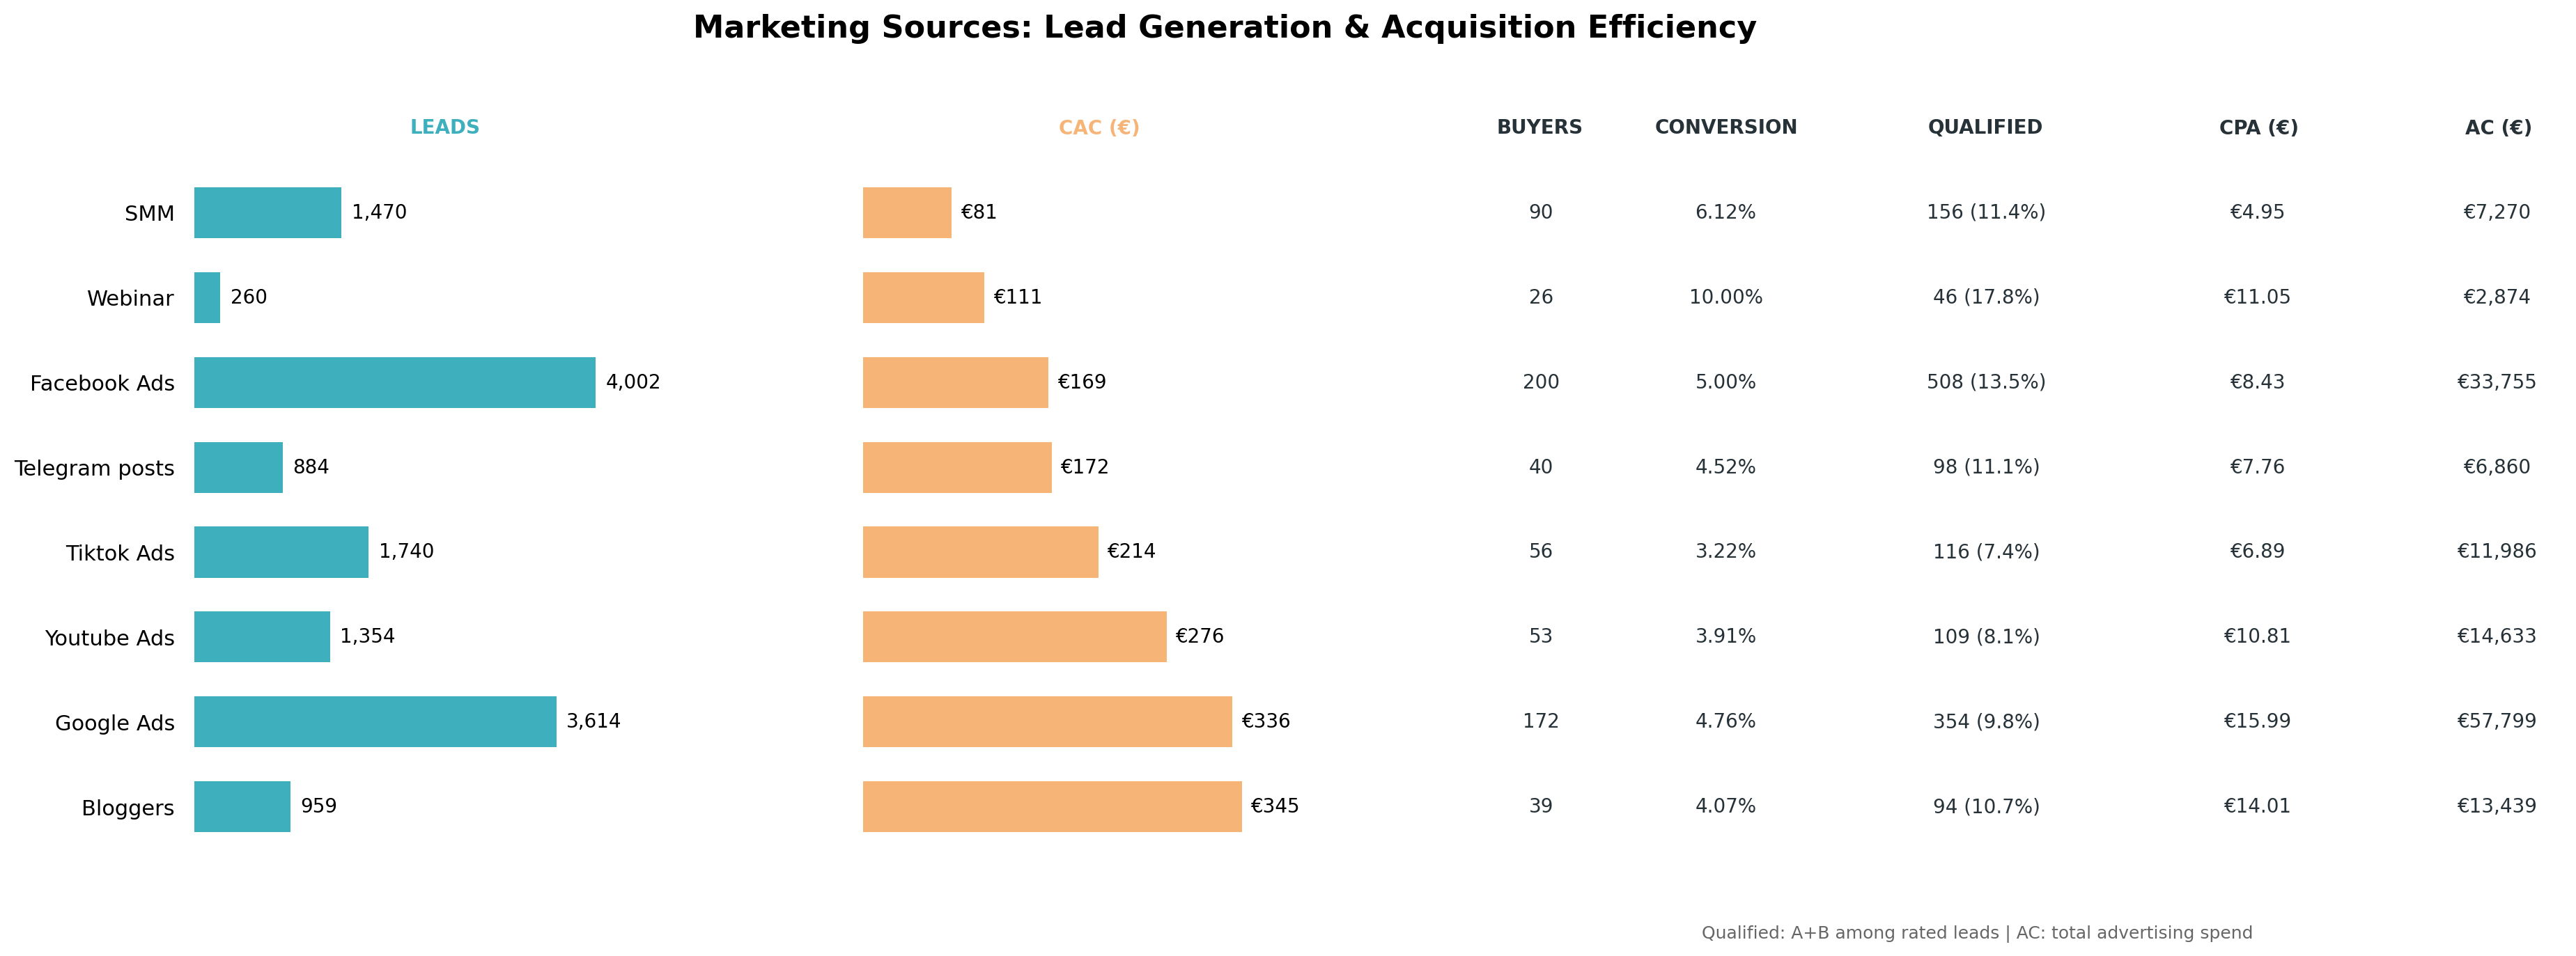

In [51]:
# @title
fig = plt.figure(figsize=(20, 7.5))

ax_leads = fig.add_axes([0.13, 0.16, 0.18, 0.65])
ax_cac = fig.add_axes([0.37, 0.16, 0.17, 0.65], sharey=ax_leads)
ax_metrics = fig.add_axes([0.59, 0.16, 0.39, 0.65], sharey=ax_leads)

y = np.arange(len(paid_sources))

ax_leads.barh(
    y,
    paid_sources["Leads"],
    color=PRIMARY_COLOR,
    height=0.6
)

ax_cac.barh(
    y,
    paid_sources["CAC"],
    color=SECONDARY_COLOR,
    height=0.6
)

ax_leads.set_xlim(0, paid_sources["Leads"].max() * 1.25)
ax_cac.set_xlim(0, paid_sources["CAC"].max() * 1.25)

ax_leads.set_yticks(y)
ax_leads.set_yticklabels(
    paid_sources["Source"],
    fontsize=11
)

ax_leads.set_ylim(len(paid_sources) - 0.5, -0.5)

for i, row in paid_sources.iterrows():
    ax_leads.text(
        row["Leads"] + paid_sources["Leads"].max() * 0.025,
        i,
        f'{row["Leads"]:,.0f}',
        va="center",
        fontsize=10
    )

    ax_cac.text(
        row["CAC"] + paid_sources["CAC"].max() * 0.025,
        i,
        f'€{row["CAC"]:,.0f}',
        va="center",
        fontsize=10
    )

    values = [
        f'{row["Buyers"]:,.0f}',
        f'{row["Conversion_Rate"]:.2f}%',
        f'{row["Qualified_Leads"]:,.0f} ({row["Qualified_Share"]:.1f}%)',
        f'€{row["CPA"]:,.2f}',
        f'€{row["AC"]:,.0f}'
    ]

    for x, value in zip(
        [0.06, 0.23, 0.47, 0.72, 0.94],
        values
    ):
        ax_metrics.text(
            x,
            i,
            value,
            transform=ax_metrics.get_yaxis_transform(),
            ha="center",
            va="center",
            fontsize=10,
            color="#263238"
        )

for ax in [ax_leads, ax_cac, ax_metrics]:
    ax.grid(False)
    ax.tick_params(
        axis="x",
        bottom=False,
        labelbottom=False
    )
    ax.spines[
        ["top", "right", "bottom", "left"]
    ].set_visible(False)

ax_leads.tick_params(axis="y", length=0, pad=10)
ax_cac.tick_params(axis="y", left=False, labelleft=False)
ax_metrics.tick_params(axis="y", left=False, labelleft=False)

ax_metrics.set_xlim(0, 1)
ax_metrics.set_xticks([])

fig.suptitle(
    "Marketing Sources: Lead Generation & Acquisition Efficiency",
    fontsize=16,
    fontweight="bold",
    y=0.96
)

headers = [
    (0.22, "LEADS", PRIMARY_COLOR),
    (0.455, "CAC (€)", SECONDARY_COLOR),
    (0.613, "BUYERS", "#263238"),
    (0.68, "CONVERSION", "#263238"),
    (0.773, "QUALIFIED", "#263238"),
    (0.871, "CPA (€)", "#263238"),
    (0.957, "AC (€)", "#263238")
]

for x, label, color in headers:
    fig.text(
        x,
        0.845,
        label,
        ha="center",
        fontsize=10,
        fontweight="bold",
        color=color
    )

fig.text(
    0.77,
    0.075,
    "Qualified: A+B among rated leads | AC: total advertising spend",
    ha="center",
    fontsize=9,
    color="#666666"
)

plt.show()

**Hypothesis: Advertising Budget Reallocation**


Based on the marketing analysis conducted in the second notebook and presented in the *Marketing Sources: Lead Generation & Acquisition Efficiency* visualization, Facebook Ads and Google Ads were identified as the two largest lead acquisition channels.

However, Facebook Ads demonstrates significantly higher acquisition efficiency: its Customer Acquisition Cost (CAC) is €168.77, compared to €336.04 for Google Ads — nearly twice as low. Facebook Ads also achieves a higher conversion rate (5.00% vs. 4.76%) and generates more leads (4,002 vs. 3,614) and paying customers (200 vs. 172), despite a substantially smaller advertising budget (€33,754.72 vs. €57,798.60).

**Hypothesis:** Reallocating part of the advertising budget from Google Ads to Facebook Ads, while keeping total advertising expenditure unchanged, could increase the number of leads and paying customers, reduce overall Customer Acquisition Cost (CAC), and improve Contribution Margin.

The expected impact will be evaluated through scenario modeling, assuming that the historical CAC and CPA of both advertising channels remain constant.

In [52]:
# @title
paid_sources = paid_sources.loc[
    paid_sources["Source"].isin(["Facebook Ads", "Google Ads"]),
    ["Source", "Leads", "Buyers", "Conversion_Rate", "CAC", "CPA", "AC"]
].reset_index(drop=True)

In [53]:
# @title
display(HTML("<h3>Advertising Channels — Before Budget Reallocation</h3>"))

display(
    paid_sources.style
    .format({
        "Leads": "{:,.0f}",
        "Buyers": "{:,.0f}",
        "Conversion_Rate": "{:.2f}%",
        "CAC": "€{:,.2f}",
        "CPA": "€{:,.2f}",
        "AC": "€{:,.2f}"
    })
    .set_table_styles([
        {
            "selector": "th.col_heading",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px 14px"),
                ("text-align", "center"),
                ("border", "none")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "1px solid #EEEEEE"),
                ("text-align", "right")
            ]
        }
    ])
    .set_properties(**{
        "background-color": "white"
    })
    .set_properties(
        subset=["Source"],
        **{
            "font-weight": "bold",
            "text-align": "left"
        }
    )
    .background_gradient(
        subset=["CAC"],
        cmap=sns.light_palette(SECONDARY_COLOR, as_cmap=True)
    )
    .hide(axis="index")
)

Source,Leads,Buyers,Conversion_Rate,CAC,CPA,AC
Facebook Ads,"4,002",200,5.00%,€168.77,€8.43,"€33,754.72"
Google Ads,"3,614",172,4.76%,€336.04,€15.99,"€57,798.60"


In [54]:
# @title
paid_sources_new = paid_sources.copy()

paid_sources_new.loc[
    paid_sources_new["Source"] == "Facebook Ads", "AC"
] = 50000

paid_sources_new.loc[
    paid_sources_new["Source"] == "Google Ads", "AC"
] = paid_sources["AC"].sum() - 50000

paid_sources_new["Leads"] = (
    paid_sources_new["AC"] / paid_sources_new["CPA"]
)

paid_sources_new["Buyers"] = (
    paid_sources_new["AC"] / paid_sources_new["CAC"]
)

paid_sources_new["Conversion_Rate"] = (
    paid_sources_new["Buyers"] / paid_sources_new["Leads"] * 100
)

In [55]:
# @title
display(HTML("<h3>Advertising Channels — After Budget Reallocation</h3>"))

display(
    paid_sources_new.style
    .format({
        "Leads": "{:,.0f}",
        "Buyers": "{:,.0f}",
        "Conversion_Rate": "{:.2f}%",
        "CAC": "€{:,.2f}",
        "CPA": "€{:,.2f}",
        "AC": "€{:,.2f}"
    })
    .set_table_styles([
        {
            "selector": "th.col_heading",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px 14px"),
                ("text-align", "center"),
                ("border", "none")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "1px solid #EEEEEE"),
                ("text-align", "right")
            ]
        }
    ])
    .set_properties(**{
        "background-color": "white"
    })
    .set_properties(
        subset=["Source"],
        **{
            "font-weight": "bold",
            "text-align": "left"
        }
    )
    .background_gradient(
        subset=["CAC"],
        cmap=sns.light_palette(SECONDARY_COLOR, as_cmap=True)
    )
    .hide(axis="index")
)

Source,Leads,Buyers,Conversion_Rate,CAC,CPA,AC
Facebook Ads,"5,928",296,5.00%,€168.77,€8.43,"€50,000.00"
Google Ads,"2,598",124,4.76%,€336.04,€15.99,"€41,553.32"


In [ ]:
delta_UA = (
    paid_sources_new["Leads"].sum()
    - paid_sources["Leads"].sum()
)

delta_B = (
    paid_sources_new["Buyers"].sum()
    - paid_sources["Buyers"].sum()
)

print(f"Change in UA: {delta_UA:+,.2f}")
print(f"Change in Buyers: {delta_B:+,.2f}")

Change in UA: +910.28
Change in Buyers: +47.91


In [ ]:
UA_new = UA_total + delta_UA
B_new = B_total + delta_B

print(f"Total UA: {UA_total:,.2f} → {UA_new:,.2f}")
print(f"Total Buyers: {B_total:,.2f} → {B_new:,.2f}")

Total UA: 18,548.00 → 19,458.28
Total Buyers: 837.00 → 884.91


In [ ]:
T_new = B_new * APC_total

C1_new = B_new / UA_new
APC_new = APC_total
AOV_new = AOV_total
COGS_new = COGS_total
AC_new = AC_total

CAC_new = AC_new / B_new
CPA_new = AC_new / UA_new

Revenue_new = T_new * AOV_new
Gross_Profit_new = Revenue_new - T_new * COGS_new

CLTV_new = Gross_Profit_new / B_new
LTV_new = Gross_Profit_new / UA_new

CM_new = Gross_Profit_new - AC_new

In [ ]:
unit_economics_comparison = unit_economics_total.copy()

unit_economics_comparison.index = ["Before"]

unit_economics_comparison.loc["After"] = [
    UA_new,
    B_new,
    T_new,
    C1_new,
    APC_new,
    AOV_new,
    COGS_new,
    AC_new,
    CAC_new,
    CPA_new,
    CLTV_new,
    LTV_new,
    Revenue_new,
    Gross_Profit_new,
    CM_new
]

In [ ]:
# @title
display(HTML("<h3>Total Unit Economics — Before vs. After</h3>"))

display(
    unit_economics_comparison.style
    .format({
        "UA": "{:,.2f}",
        "B": "{:,.2f}",
        "T": "{:,.2f}",
        "C1": "{:.2%}",
        "APC": "{:.2f}",
        "AOV": "{:,.2f}",
        "COGS": "{:,.2f}",
        "AC": "{:,.2f}",
        "CAC": "{:,.2f}",
        "CPA": "{:,.2f}",
        "CLTV": "{:,.2f}",
        "LTV": "{:,.2f}",
        "Revenue": "{:,.2f}",
        "Gross Profit": "{:,.2f}",
        "CM": "{:,.2f}"
    })
    .set_table_styles([
        {
            "selector": "th.col_heading",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px 14px"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "th.row_heading",
            "props": [
                ("background-color", "white"),
                ("font-weight", "bold"),
                ("padding", "10px 14px")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "10px 14px"),
                ("border-bottom", "1px solid #EEEEEE"),
                ("text-align", "right")
            ]
        }
    ])
    .set_properties(**{"background-color": "white"})
    .background_gradient(
        subset=["CM"],
        cmap=sns.light_palette(SECONDARY_COLOR, as_cmap=True)
    )
)

,UA,B,T,C1,APC,AOV,COGS,AC,CAC,CPA,CLTV,LTV,Revenue,Gross Profit,CM
Before,"18,548.00",837.00,"4,367.00",4.51%,5.22,808.87,0.00,"148,915.24",177.92,8.03,"4,220.22",190.44,"3,532,325.00","3,532,325.00","3,383,409.76"
After,"19,458.28",884.91,"4,616.97",4.55%,5.22,808.87,0.00,"148,915.24",168.28,7.65,"4,220.22",191.92,"3,734,521.44","3,734,521.44","3,585,606.20"


In [ ]:
hypothesis_impact = pd.DataFrame({
    "Metric": ["CAC", "CM"],
    "Before": [CAC_total, CM_total],
    "After": [CAC_new, CM_new]
})

hypothesis_impact["Change (€)"] = (
    hypothesis_impact["After"] - hypothesis_impact["Before"]
)

hypothesis_impact["Change (%)"] = (
    hypothesis_impact["Change (€)"] / hypothesis_impact["Before"] * 100
)

In [ ]:
# @title
display(HTML("<h3>Total Unit Economics — Before vs. After</h3>"))

display(
    hypothesis_impact.style
    .format({
        "Before": "€{:,.2f}",
        "After": "€{:,.2f}",
        "Change (€)": "{:+,.2f} €",
        "Change (%)": "{:+.2f}%"
    })
    .set_table_styles([
        {
            "selector": "th.col_heading",
            "props": [
                ("background-color", PRIMARY_COLOR),
                ("color", "white"),
                ("font-weight", "bold"),
                ("padding", "12px 18px"),
                ("text-align", "center")
            ]
        },
        {
            "selector": "td",
            "props": [
                ("padding", "12px 18px"),
                ("border-bottom", "1px solid #EEEEEE"),
                ("text-align", "right")
            ]
        }
    ])
    .set_properties(**{
        "background-color": "white"
    })
    .set_properties(
        subset=["Metric"],
        **{
            "font-weight": "bold",
            "text-align": "left"
        }
    )
    .background_gradient(
        subset=["Change (%)"],
        cmap=sns.light_palette(SECONDARY_COLOR, as_cmap=True)
    )
    .hide(axis="index")
)

Metric,Before,After,Change (€),Change (%)
CAC,€177.92,€168.28,-9.63 €,-5.41%
CM,"€3,383,409.76","€3,585,606.20","+202,196.44 €",+5.98%


**Hypothesis Results: Advertising Budget Reallocation**


Based on the marketing acquisition analysis, Facebook Ads demonstrated substantially lower Customer Acquisition Cost (CAC) than Google Ads (€168.77 vs. €336.04).

To improve acquisition efficiency, the proposed scenario reallocates €16,245.28 from Google Ads to Facebook Ads, increasing the Facebook Ads budget to €50,000 while reducing the Google Ads budget to €41,553.32. The total advertising budget remains unchanged.

Assuming constant channel-level CAC and CPA, the model predicts:

- **Additional leads:** +910.28
- **Additional buyers:** +47.91
- **Total leads:** 18,548 → 19,458.28
- **Total buyers:** 837 → 884.91
- **Overall CAC:** approximately €177.92 → €168.28

The projected reduction in overall CAC is approximately **5.42%**, indicating improved customer acquisition efficiency without increasing advertising expenditure.

The model also predicts an increase in Contribution Margin as a result of acquiring more paying customers at the same total advertising cost.

These results represent a scenario-based forecast rather than an observed improvement. The hypothesis requires experimental validation.

# 3. Hypothesis Validation & Experimental Design

**Business Hypothesis Validation — Methodology**

**Objective:** To determine whether reallocating the advertising budget between Facebook Ads and Google Ads can reduce the overall Customer Acquisition Cost (CAC) without increasing total advertising spend. Scenario modelling predicts a 5.41% reduction in CAC.

**Primary Metric:** CAC — Customer Acquisition Cost.

**H₀ (Null Hypothesis):** The new advertising budget allocation strategy does not achieve a 5.41% reduction in CAC.

**H₁ (Alternative Hypothesis):** The new advertising budget allocation strategy reduces CAC by 5.41%.

**Validation Method:** A controlled comparison of two advertising strategies. The control group maintains the existing budget allocation, while the test group uses an increased share of Facebook Ads. The experiment involves randomly assigning the audience to independent, non-overlapping groups, running both strategies simultaneously, maintaining equal total budgets, and ensuring comparable advertising and business conditions.

**Success Criterion:** A statistically significant reduction in CAC in the test group at a 5% significance level. The expected effect of −5.41% serves as a benchmark for comparison with the observed result. Statistical validation is planned using a one-sided confidence interval for the ratio of CAC in the test and control groups.

**Justification for Not Calculating Sample Size:** CAC is an aggregated metric. The available historical values are calculated at the advertising channel level and do not allow direct estimation of variability across independent experimental observations. The weekly standard deviation of CAC also cannot be used in a standard sample size formula without additional assumptions. Sample size and experiment duration can be calculated once the unit of randomization, the available number of observations, and the variability of the metric have been determined.

**Expected Result:** Scenario modelling predicts a reduction in overall CAC from €177.92 to €168.28 (−5.41%) and an increase in Contribution Margin of €202,196.44 (+5.98%), with the total advertising budget remaining unchanged.

**Conclusion:** The proposed strategy demonstrates positive economic potential. Scenario modelling indicates that the target effect is achievable under the specified assumptions, while experimental validation is required to determine whether this effect can be achieved in practice.

In [ ]:
# @title
target_reduction = 0.05

facebook_before = paid_sources.loc[
    paid_sources["Source"].eq("Facebook Ads"), "AC"
].iloc[0]

google_before = paid_sources.loc[
    paid_sources["Source"].eq("Google Ads"), "AC"
].iloc[0]

facebook_after = paid_sources_new.loc[
    paid_sources_new["Source"].eq("Facebook Ads"), "AC"
].iloc[0]

google_after = paid_sources_new.loc[
    paid_sources_new["Source"].eq("Google Ads"), "AC"
].iloc[0]

target_cac = CAC_total * (1 - target_reduction)

In [ ]:
# @title
def draw_card(x, y, w, h, title, body, color):
    card = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.15,rounding_size=0.15",
        linewidth=1.3,
        edgecolor=color,
        facecolor="white"
    )
    ax.add_patch(card)

    ax.text(
        x + 0.25, y + h - 0.35,
        title,
        fontsize=13,
        fontweight="bold",
        color=color,
        va="top"
    )

    ax.text(
        x + 0.25, y + h - 0.95,
        body,
        fontsize=11,
        color="#263238",
        va="top",
        linespacing=1.6
    )

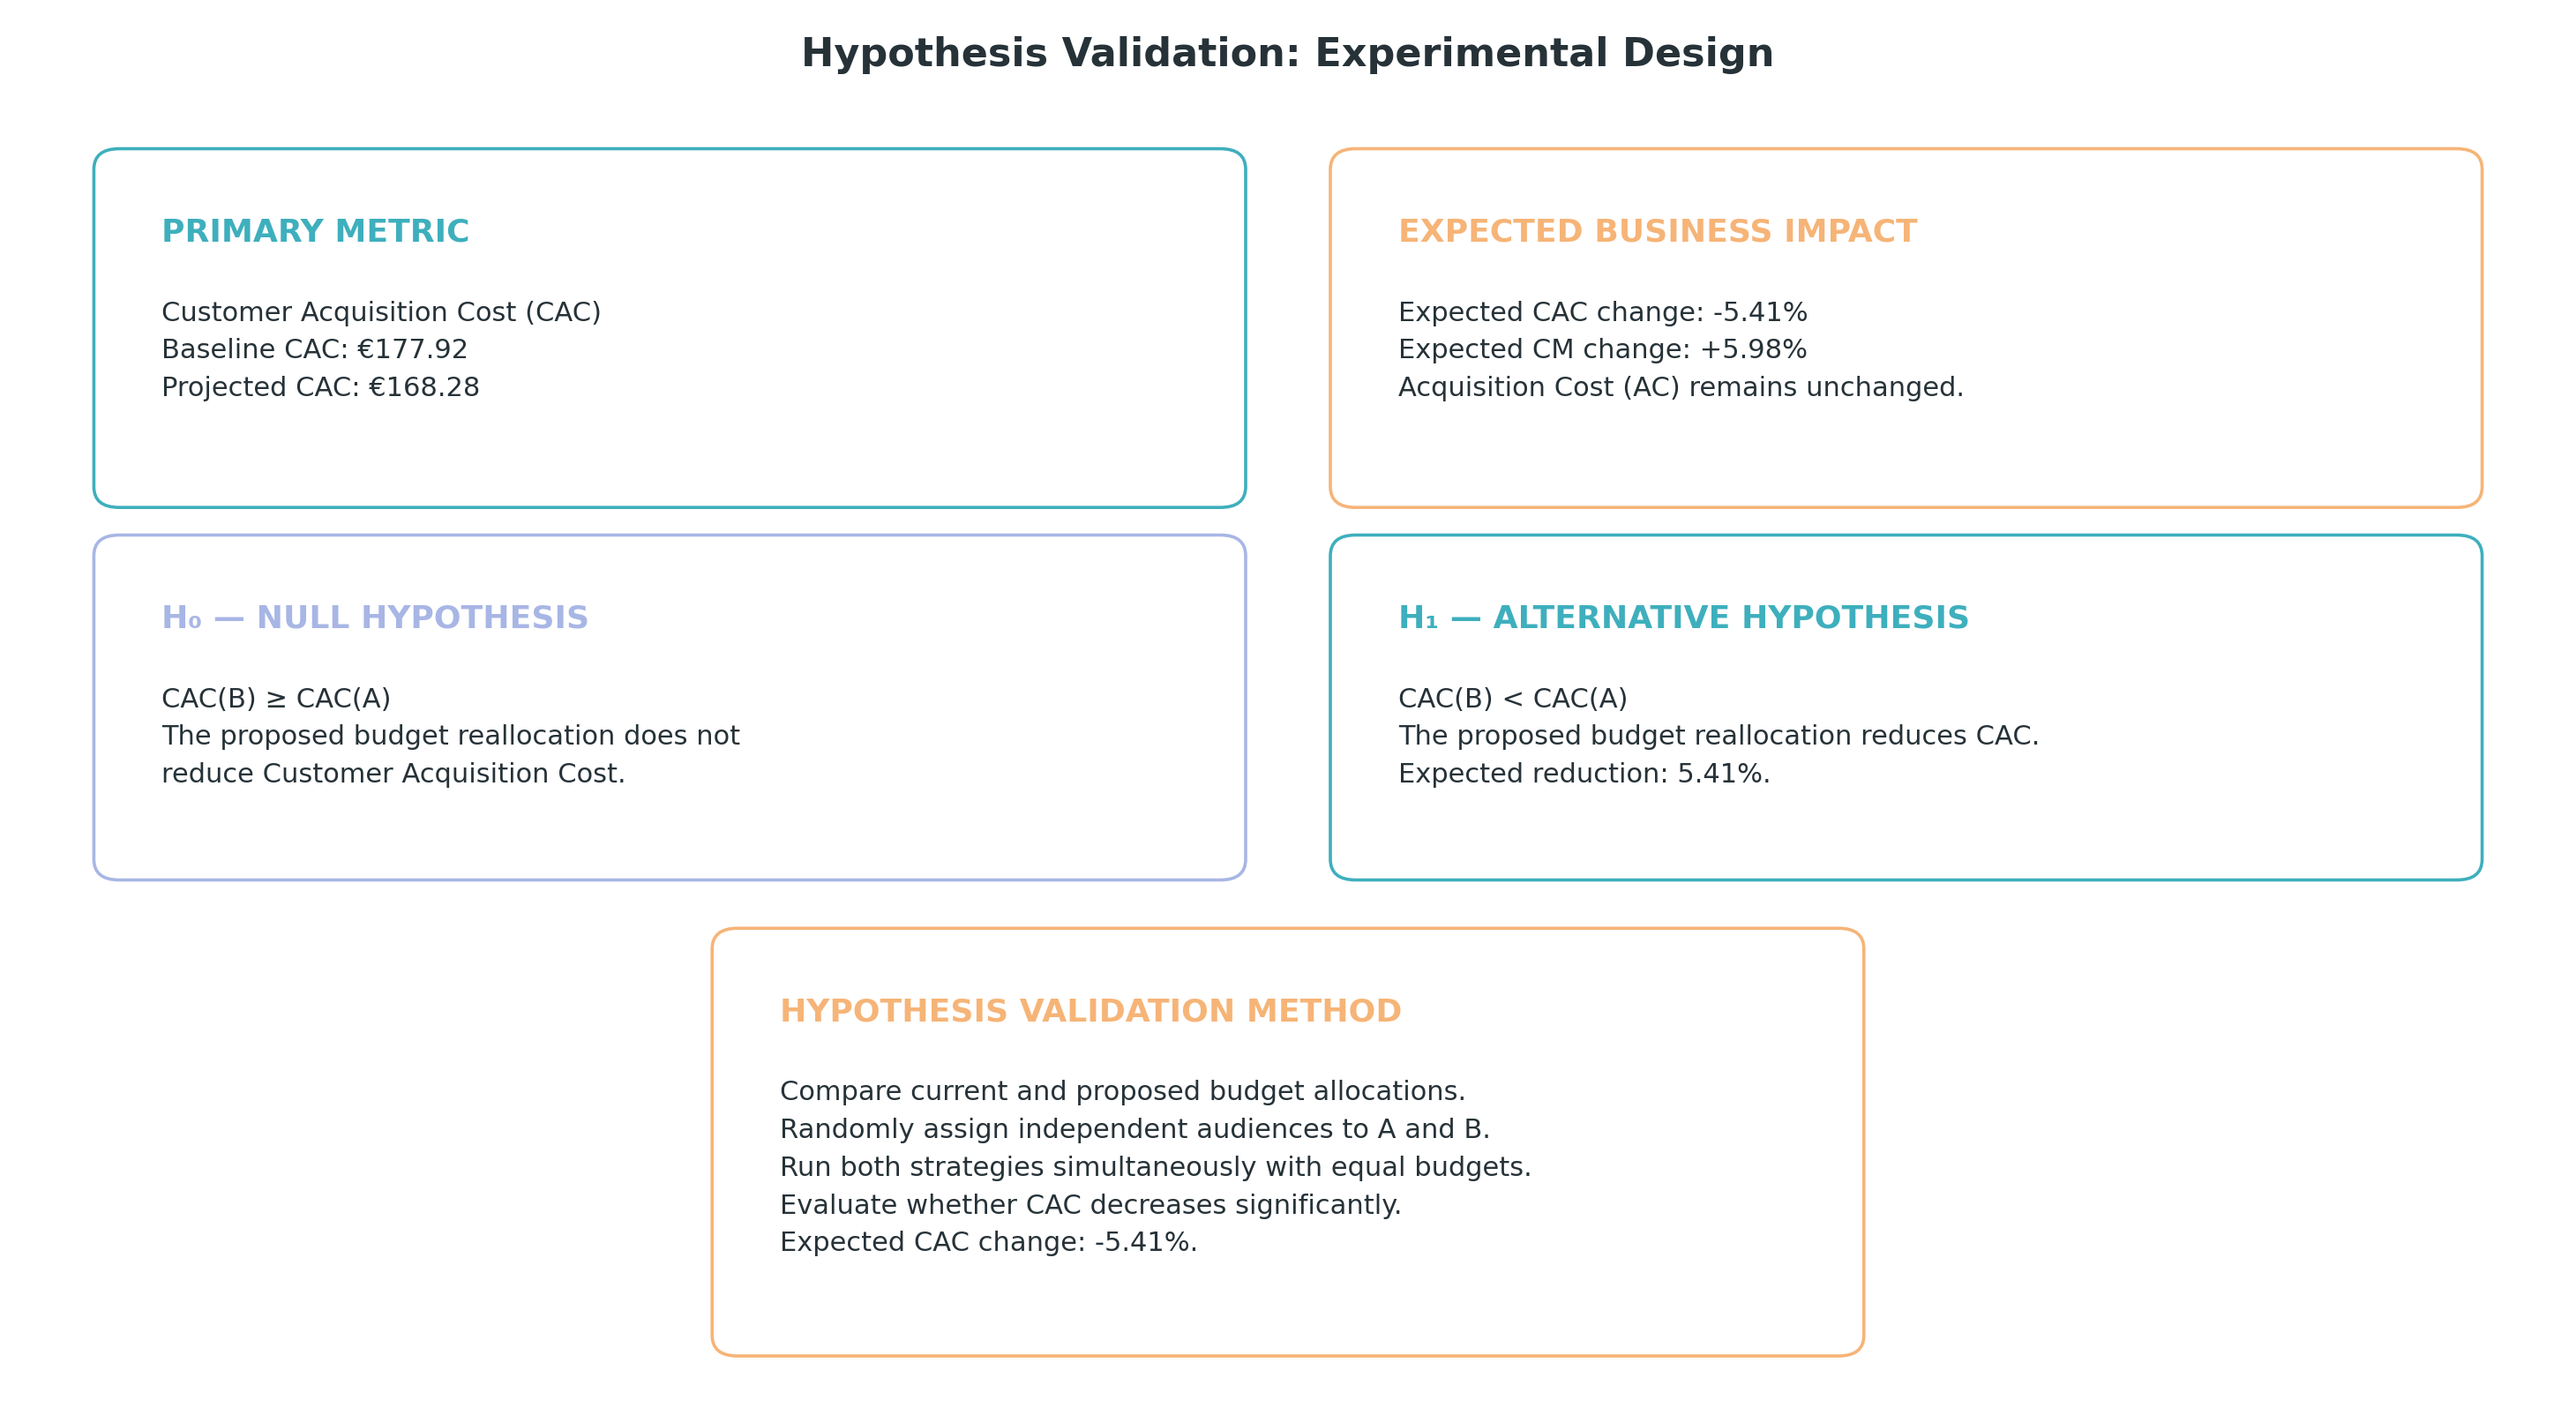

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(15, 8.5))
ax.set_xlim(0, 15)
ax.set_ylim(0, 10)
ax.axis("off")



ax.text(
    7.5, 9.65,
    "Hypothesis Validation: Experimental Design",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="#263238"
)

draw_card(
    0.6, 6.6, 6.5, 2.3,
    "PRIMARY METRIC",
    f"Customer Acquisition Cost (CAC)\n"
    f"Baseline CAC: €{CAC_total:,.2f}\n"
    f"Projected CAC: €{CAC_new:,.2f}",
    PRIMARY_COLOR
)

draw_card(
    7.9, 6.6, 6.5, 2.3,
    "EXPECTED BUSINESS IMPACT",
    f"Expected CAC change: {(CAC_new / CAC_total - 1) * 100:+.2f}%\n"
    f"Expected CM change: {(CM_new / CM_total - 1) * 100:+.2f}%\n"
    f"Acquisition Cost (AC) remains unchanged.",
    SECONDARY_COLOR
)

draw_card(
    0.6, 3.9, 6.5, 2.2,
    "H₀ — NULL HYPOTHESIS",
    "CAC(B) ≥ CAC(A)\n"
    "The proposed budget reallocation does not\n"
    "reduce Customer Acquisition Cost.",
    NEUTRAL_COLOR
)

draw_card(
    7.9, 3.9, 6.5, 2.2,
    "H₁ — ALTERNATIVE HYPOTHESIS",
    "CAC(B) < CAC(A)\n"
    "The proposed budget reallocation reduces CAC.\n"
    f"Expected reduction: {(1 - CAC_new / CAC_total) * 100:.2f}%.",
    PRIMARY_COLOR
)

draw_card(
    4.25, 0.45, 6.5, 2.8,
    "HYPOTHESIS VALIDATION METHOD",
    "Compare current and proposed budget allocations.\n"
    "Randomly assign independent audiences to A and B.\n"
    "Run both strategies simultaneously with equal budgets.\n"
    "Evaluate whether CAC decreases significantly.\n"
    f"Expected CAC change: {(CAC_new / CAC_total - 1) * 100:+.2f}%.",
    SECONDARY_COLOR
)

plt.subplots_adjust(
    left=0.02,
    right=0.98,
    top=0.96,
    bottom=0.04
)

plt.show()

In [ ]:
budget_before = facebook_before + google_before
budget_after = facebook_after + google_after

In [ ]:
# @title
fig = go.Figure()

fig.add_trace(
    go.Bar(
        y=["Control A", "Treatment B"],
        x=[
            facebook_before / budget_before * 100,
            facebook_after / budget_after * 100
        ],
        name="Facebook Ads",
        orientation="h",
        marker_color=PRIMARY_COLOR,
        text=[
            f"€{facebook_before:,.2f}<br>"
            f"{facebook_before / budget_before * 100:.1f}%",
            f"€{facebook_after:,.2f}<br>"
            f"{facebook_after / budget_after * 100:.1f}%"
        ],
        textposition="inside",
        insidetextanchor="middle",
        textfont=dict(size=14, color="white"),
        customdata=[facebook_before, facebook_after],
        hovertemplate=(
            "<b>%{y} — Facebook Ads</b><br>"
            "Budget: €%{customdata:,.2f}<br>"
            "Budget Share: %{x:.2f}%"
            "<extra></extra>"
        )
    )
)

fig.add_trace(
    go.Bar(
        y=["Control A", "Treatment B"],
        x=[
            google_before / budget_before * 100,
            google_after / budget_after * 100
        ],
        name="Google Ads",
        orientation="h",
        marker_color=SECONDARY_COLOR,
        text=[
            f"€{google_before:,.2f}<br>"
            f"{google_before / budget_before * 100:.1f}%",
            f"€{google_after:,.2f}<br>"
            f"{google_after / budget_after * 100:.1f}%"
        ],
        textposition="inside",
        insidetextanchor="middle",
        textfont=dict(size=14, color="#263238"),
        customdata=[google_before, google_after],
        hovertemplate=(
            "<b>%{y} — Google Ads</b><br>"
            "Budget: €%{customdata:,.2f}<br>"
            "Budget Share: %{x:.2f}%"
            "<extra></extra>"
        )
    )
)

fig.update_layout(
    title=dict(
        text="<b>Control vs. Treatment: Advertising Budget Allocation</b>",
        x=0.5,
        xanchor="center",
        font=dict(size=16, color="#263238")
    ),
    barmode="stack",
    width=1250,
    height=470,
    paper_bgcolor="white",
    plot_bgcolor="white",
    font=dict(size=13, color="#263238"),
    xaxis=dict(
        title="Budget Share (%)",
        range=[0, 105],
        ticksuffix="%",
        dtick=20,
        showgrid=True,
        gridcolor="#EAEFF1",
        zeroline=False
    ),
    yaxis=dict(
        title=None,
        categoryorder="array",
        categoryarray=["Treatment B", "Control A"]
    ),
    legend=dict(
        orientation="h",
        x=0.5,
        xanchor="center",
        y=-0.25
    ),
    margin=dict(l=140, r=55, t=90, b=100),
    bargap=0.45
)

fig.add_annotation(
    x=50,
    y=-0.25,
    xref="x",
    yref="paper",
    text=(
        f"<b>Combined budget: €{budget_before:,.2f}</b>"
        " | Total advertising expenditure remains unchanged"
    ),
    showarrow=False,
    font=dict(size=12, color="#64757B")
)

fig.show()

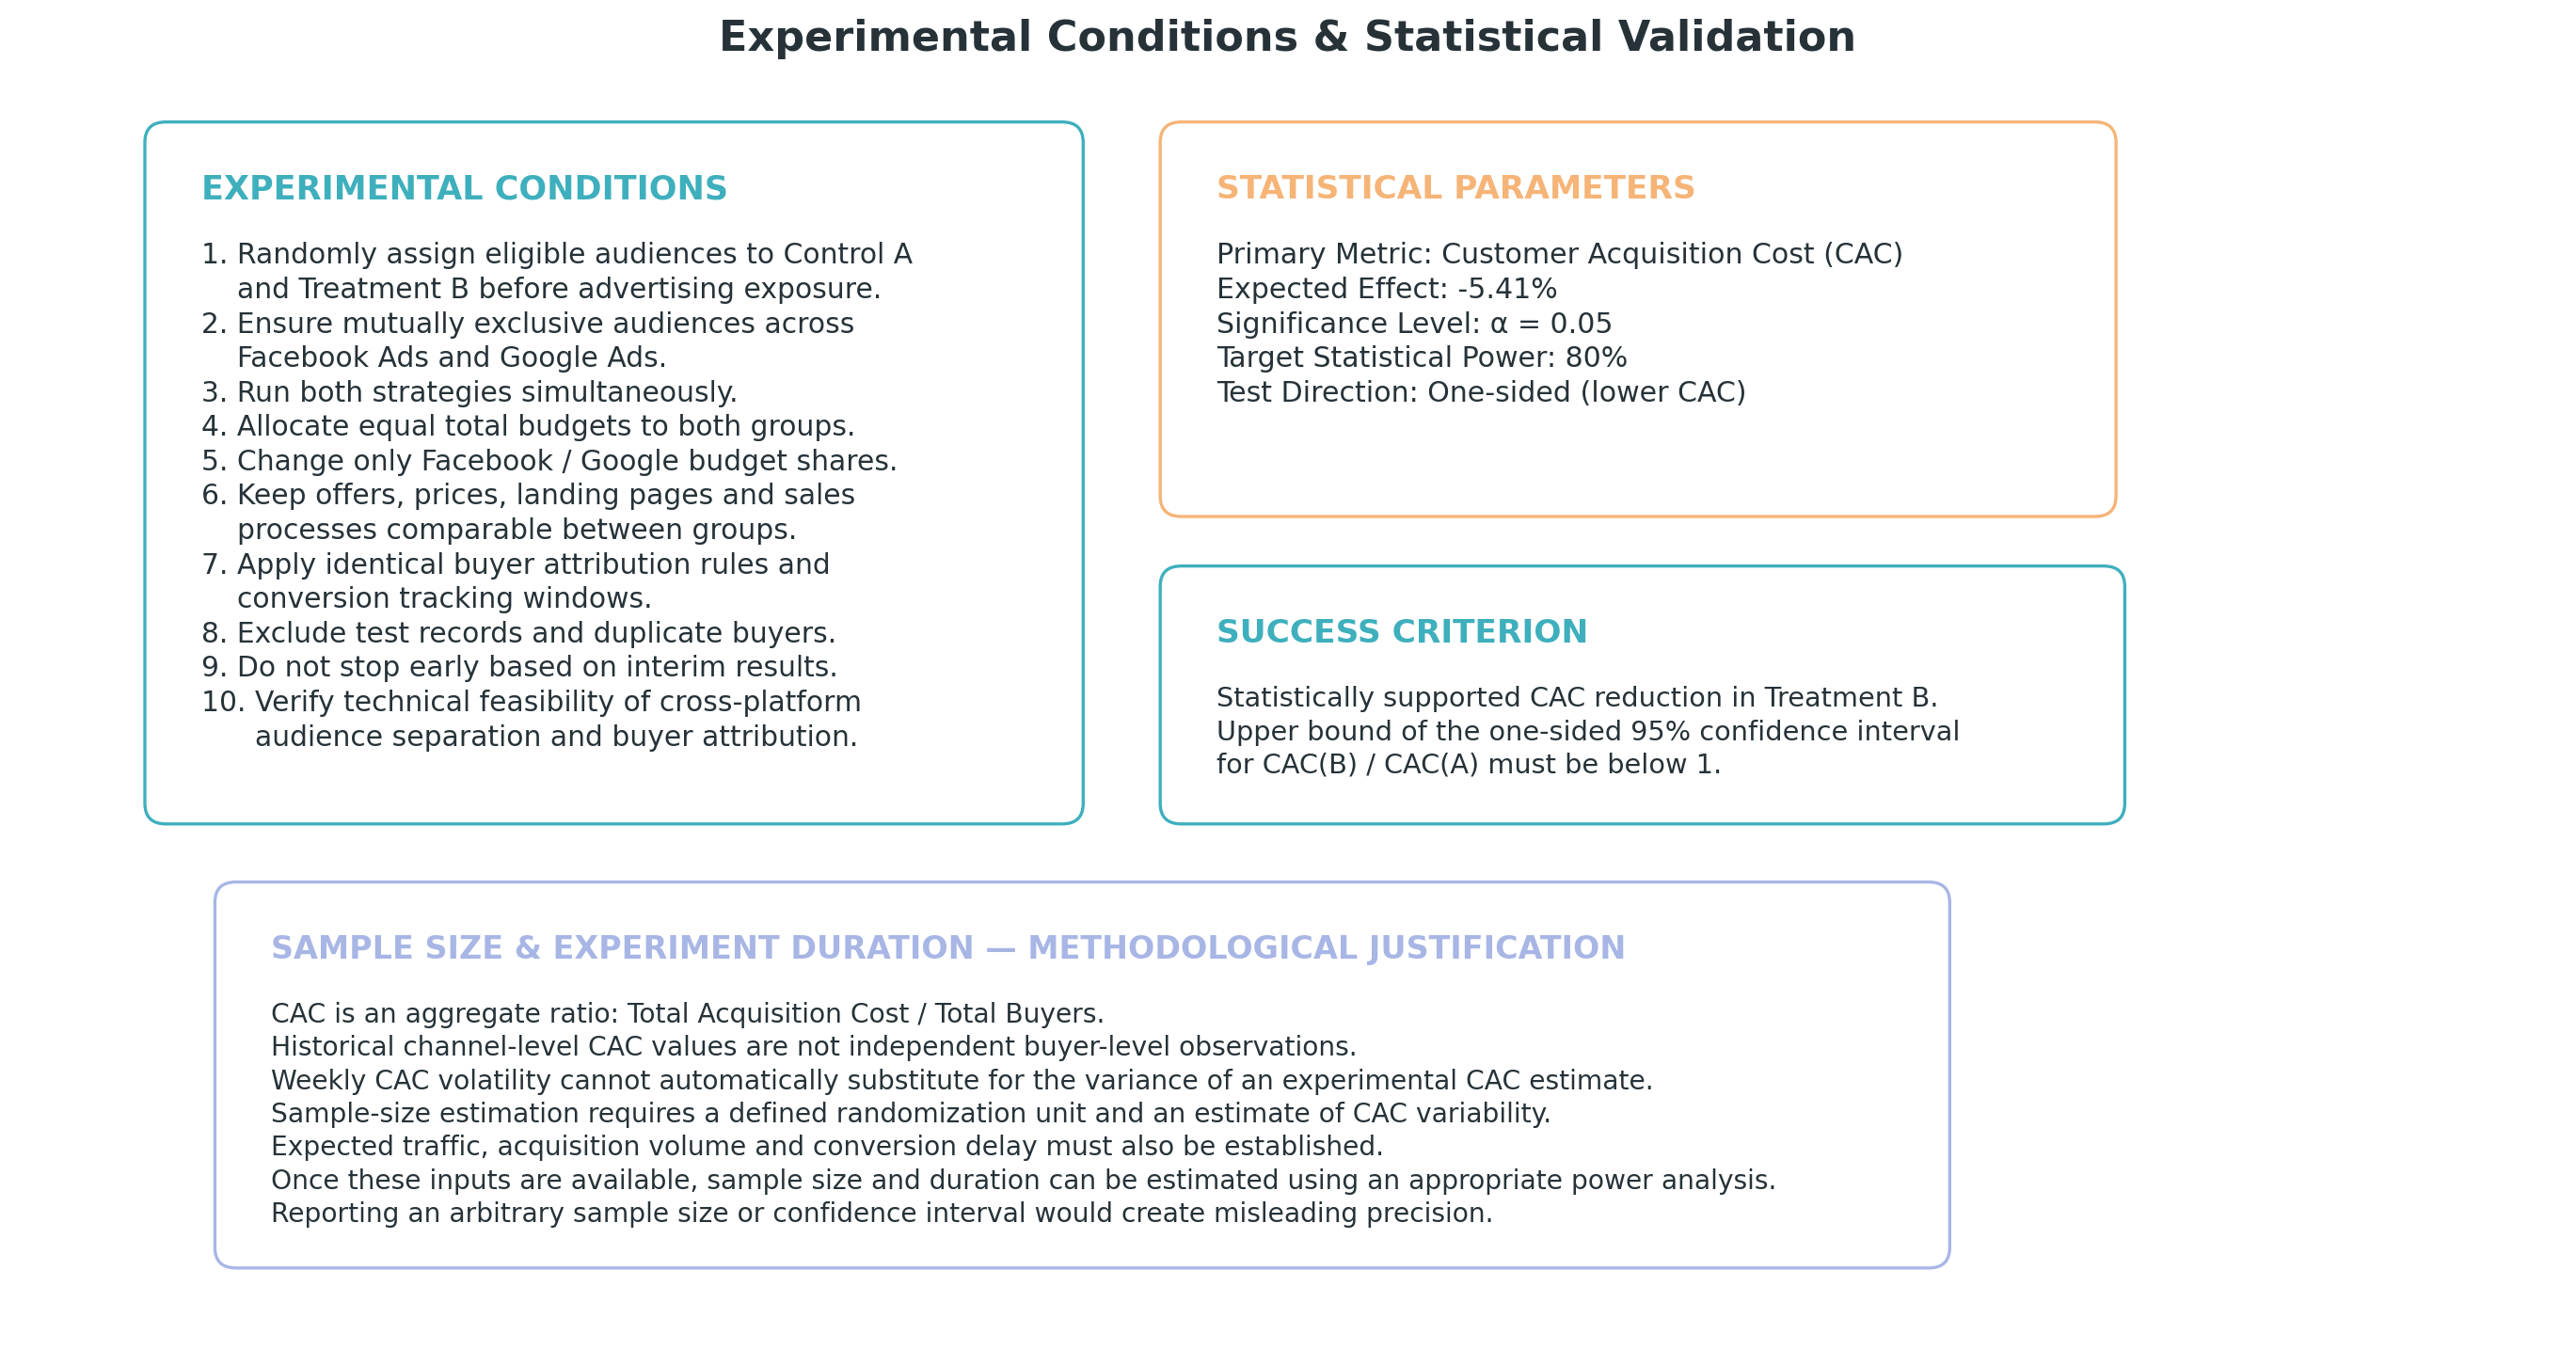

In [ ]:
# @title
fig, ax = plt.subplots(figsize=(14.2, 7.4))
ax.set_xlim(0, 14.5)
ax.set_ylim(0, 7.5)
ax.axis("off")

fig.patch.set_facecolor("white")

def draw_info_card(x, y, w, h, title, content, color, title_fs=12.5, text_fs=10.8):
    card = FancyBboxPatch(
        (x, y), w, h,
        boxstyle="round,pad=0.08,rounding_size=0.12",
        linewidth=1.2,
        edgecolor=color,
        facecolor="white"
    )
    ax.add_patch(card)

    ax.text(
        x + 0.24,
        y + h - 0.22,
        title,
        fontsize=title_fs,
        fontweight="bold",
        color=color,
        va="top"
    )

    ax.text(
        x + 0.24,
        y + h - 0.62,
        content,
        fontsize=text_fs,
        color="#263238",
        va="top",
        linespacing=1.33
    )

ax.text(
    7.25, 7.5,
    "Experimental Conditions & Statistical Validation",
    ha="center",
    fontsize=16,
    fontweight="bold",
    color="#263238"
)

draw_info_card(
    0.80, 3.05, 5.2, 3.95,
    "EXPERIMENTAL CONDITIONS",
    "1. Randomly assign eligible audiences to Control A\n"
    "    and Treatment B before advertising exposure.\n"
    "2. Ensure mutually exclusive audiences across\n"
    "    Facebook Ads and Google Ads.\n"
    "3. Run both strategies simultaneously.\n"
    "4. Allocate equal total budgets to both groups.\n"
    "5. Change only Facebook / Google budget shares.\n"
    "6. Keep offers, prices, landing pages and sales\n"
    "    processes comparable between groups.\n"
    "7. Apply identical buyer attribution rules and\n"
    "    conversion tracking windows.\n"
    "8. Exclude test records and duplicate buyers.\n"
    "9. Do not stop early based on interim results.\n"
    "10. Verify technical feasibility of cross-platform\n"
    "      audience separation and buyer attribution.",
    PRIMARY_COLOR,
    title_fs=12.6,
    text_fs=10.7
)

draw_info_card(
    6.6, 4.85, 5.3, 2.15,
    "STATISTICAL PARAMETERS",
    "Primary Metric: Customer Acquisition Cost (CAC)\n"
    f"Expected Effect: {(CAC_new / CAC_total - 1) * 100:+.2f}%\n"
    "Significance Level: α = 0.05\n"
    "Target Statistical Power: 80%\n"
    "Test Direction: One-sided (lower CAC)",
    SECONDARY_COLOR,
    title_fs=12.4,
    text_fs=10.8
)

draw_info_card(
    6.6, 3.05, 5.35, 1.35,
    "SUCCESS CRITERION",
    "Statistically supported CAC reduction in Treatment B.\n"
    "Upper bound of the one-sided 95% confidence interval\n"
    "for CAC(B) / CAC(A) must be below 1.",
    PRIMARY_COLOR,
    title_fs=12.4,
    text_fs=10.35
)

draw_info_card(
    1.2, 0.45, 9.75, 2.10,
    "SAMPLE SIZE & EXPERIMENT DURATION — METHODOLOGICAL JUSTIFICATION",
    "CAC is an aggregate ratio: Total Acquisition Cost / Total Buyers.\n"
    "Historical channel-level CAC values are not independent buyer-level observations.\n"
    "Weekly CAC volatility cannot automatically substitute for the variance of an experimental CAC estimate.\n"
    "Sample-size estimation requires a defined randomization unit and an estimate of CAC variability.\n"
    "Expected traffic, acquisition volume and conversion delay must also be established.\n"
    "Once these inputs are available, sample size and duration can be estimated using an appropriate power analysis.\n"
    "Reporting an arbitrary sample size or confidence interval would create misleading precision.",
    NEUTRAL_COLOR,
    title_fs=12.0,
    text_fs=10.15
)

plt.subplots_adjust(
    left=0.025,
    right=0.975,
    top=0.965,
    bottom=0.045
)

plt.show()

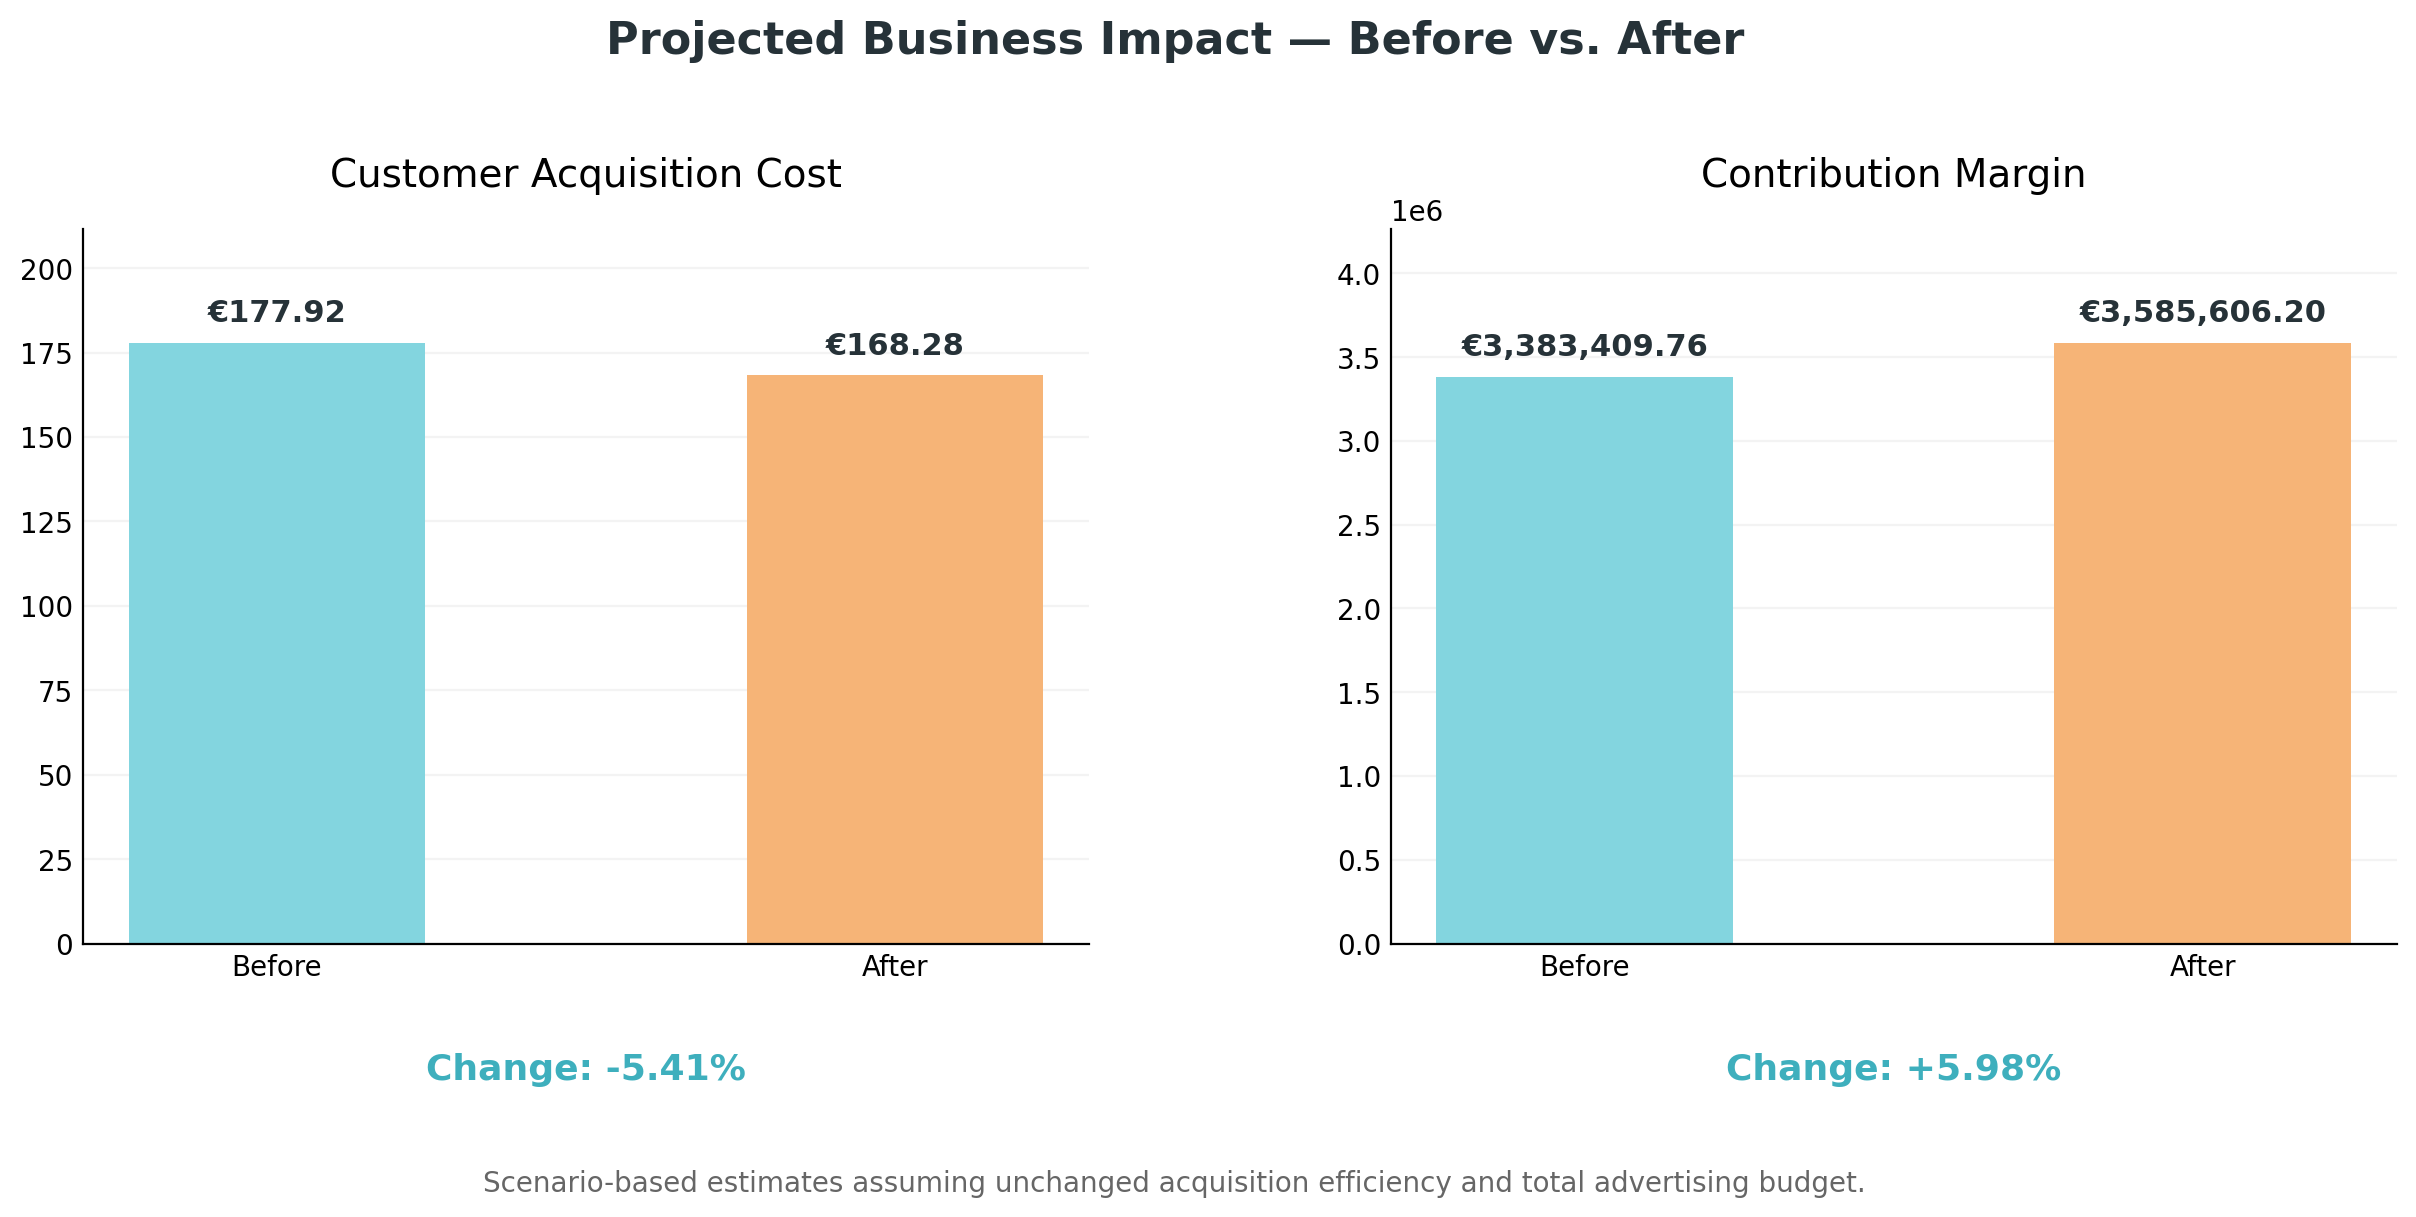

In [ ]:
# @title
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))

metrics = [
    ("CAC", "Customer Acquisition Cost"),
    ("CM", "Contribution Margin")
]

for ax, (metric, title) in zip(axes, metrics):
    row = hypothesis_impact.loc[
        hypothesis_impact["Metric"].eq(metric)
    ].iloc[0]

    values = [row["Before"], row["After"]]

    bars = ax.bar(
        ["Before", "After"],
        values,
        color=[ACCENT_COLOR, SECONDARY_COLOR],
        width=0.48
    )

    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(values) * 0.025,
            f"€{value:,.2f}",
            ha="center",
            va="bottom",
            fontsize=11,
            fontweight="bold",
            color="#263238"
        )

    ax.text(
        0.5,
        -0.19,
        f'Change: {row["Change (%)"]:+.2f}%',
        transform=ax.transAxes,
        ha="center",
        fontsize=13,
        fontweight="bold",
        color=PRIMARY_COLOR
    )

    ax.set_title(
        title,
        fontsize=14,
        # fontweight="bold",
        pad=15
    )

    ax.set_ylim(0, max(values) * 1.19)
    ax.grid(axis="y", alpha=0.15)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="both", length=0)

fig.suptitle(
    "Projected Business Impact — Before vs. After",
    fontsize=16,
    fontweight="bold",
    y=1.03,
    color="#263238"
)

fig.text(
    0.5,
    -0.035,
    "Scenario-based estimates assuming unchanged acquisition efficiency and total advertising budget.",
    ha="center",
    fontsize=10,
    color="#666666"
)

plt.subplots_adjust(
    left=0.08,
    right=0.97,
    top=0.84,
    bottom=0.19,
    wspace=0.30
)

plt.show()

###  **Conclusion — Business Growth Hypothesis & Validation**

Marketing performance analysis identified **Facebook Ads as a more cost-efficient customer acquisition channel than Google Ads**, with a CAC of €168.77 compared to €336.04.

Based on these findings, a budget reallocation strategy was proposed: increase Facebook Ads spending to €50,000 while reducing Google Ads spending to €41,553.32, keeping the combined advertising budget unchanged.

Scenario modeling predicts **approximately 48 additional buyers, a 5.41% reduction in overall CAC (€177.92 → €168.28), and a 5.98% increase in Contribution Margin**. These results suggest that reallocating the existing advertising budget could improve acquisition efficiency and business profitability without additional marketing expenditure.

To validate the hypothesis, a controlled experiment comparing the current and proposed budget allocations is recommended. The experiment should use independent, randomly assigned audiences, equal budgets, simultaneous execution, and consistent customer attribution. **CAC is the sole primary evaluation metric**, with an expected reduction of 5.41%.

Sample size and experiment duration are not calculated at this stage because the available aggregated CAC values do not provide the variability required for a statistically valid power analysis.

**The proposed strategy demonstrates positive business potential, while its actual effectiveness remains subject to experimental validation.**

## Illustrative A/B Test Sample Size Calculation


**Purpose and Methodological Limitations**

This section demonstrates the sample size estimation procedure using historical daily CAC variability.

Since CAC is an aggregate ratio metric, the calculated standard deviation does not represent individual buyer-level variability. Therefore, the resulting sample size and test duration are not statistically valid for planning the actual A/B test.

The calculations below are provided exclusively as an illustrative application of the statistical formula.


Formula:


$$
n = \frac{2(Z_{1-\alpha/2} + Z_{1-\beta})^2 \cdot \sigma^2}{\Delta^2}
$$


| Parameter | Value | Description |
|---|---|---|
| $\mu_1$ | €177.92 | Baseline CAC |
| $\mu_2$ | €168.28 | Target CAC |
| $\Delta$ | €9.64 | Expected absolute difference |
| $\sigma$ | €170.60 | Historical standard deviation of daily CAC |
| $\alpha$ | 0.05 | Significance level (5%) |
| $\beta$ | 0.20 | Type II error probability (20%) |
| $1-\beta$ | 0.80 | Statistical power (80%) |
| $Z_{1-\alpha/2}$ | 1.96 | Critical Z-value for a two-sided test |
| $Z_{1-\beta}$ | 0.84 | Critical Z-value for statistical power |
| $n$ | 4,922 | Estimated daily observations per group |
| $N = 2n$ | 9,844 | Total estimated daily observations |


In [ ]:
daily_spend = spend.groupby(
    spend["Date"].dt.normalize()
)["Spend"].sum()

daily_buyers = (
    deals.loc[
        (deals["Stage"] == "Payment Done")
        & (~deals["Demo Access"])
    ]
    .groupby(deals["Created Time"].dt.normalize())["Contact Name"]
    .nunique()
)

daily_cac = pd.concat(
    [daily_spend.rename("AC"), daily_buyers.rename("B")],
    axis=1
).fillna(0)

daily_cac = daily_cac[daily_cac["B"] > 0]
daily_cac["CAC"] = daily_cac["AC"] / daily_cac["B"]

sigma_cac = daily_cac["CAC"].std(ddof=1)

print(f"Daily observations: {len(daily_cac)}")
print(f"Mean daily CAC: €{daily_cac['CAC'].mean():,.2f}")
print(f"CAC standard deviation: €{sigma_cac:,.2f}")

Daily observations: 289
Mean daily CAC: €210.12
CAC standard deviation: €170.60


In [ ]:
alpha = 0.05
power = 0.80

cac_before = unit_economics_total.loc["Total", "CAC"]
cac_after = 168.28

delta_cac = abs(cac_after - cac_before)

z_alpha = norm.ppf(1 - alpha / 2)
z_beta = norm.ppf(power)

n_per_group = int(np.ceil(
    2 * (z_alpha + z_beta)**2
    * sigma_cac**2
    / delta_cac**2
))

n_total = 2 * n_per_group

print(f"Baseline CAC: €{cac_before:,.2f}")
print(f"Target CAC: €{cac_after:,.2f}")
print(f"Absolute difference: €{delta_cac:,.2f}")
print(f"Standard deviation: €{sigma_cac:,.2f}")
print(f"Sample size per group: {n_per_group:,}")
print(f"Total sample size: {n_total:,}")

Baseline CAC: €177.92
Target CAC: €168.28
Absolute difference: €9.64
Standard deviation: €170.60
Sample size per group: 4,922
Total sample size: 9,844


In [ ]:
n_days = (
    deals["Created Time"].max().normalize()
    - deals["Created Time"].min().normalize()
).days + 1

buyers_per_day = unit_economics_total.loc["Total", "B"] / n_days

test_duration = int(np.ceil(n_total / buyers_per_day))

print(f"Historical period: {n_days} days")
print(f"Total buyers: {unit_economics_total.loc['Total', 'B']:,.0f}")
print(f"Average buyers per day: {buyers_per_day:.2f}")
print(f"Assumed required buyers: {n_total:,}")
print(f"Illustrative test duration: {test_duration:,} days")
print(f"Illustrative test duration: {test_duration / 365:.1f} years")

Historical period: 355 days
Total buyers: 837
Average buyers per day: 2.36
Assumed required buyers: 9,844
Illustrative test duration: 4,176 days
Illustrative test duration: 11.4 years


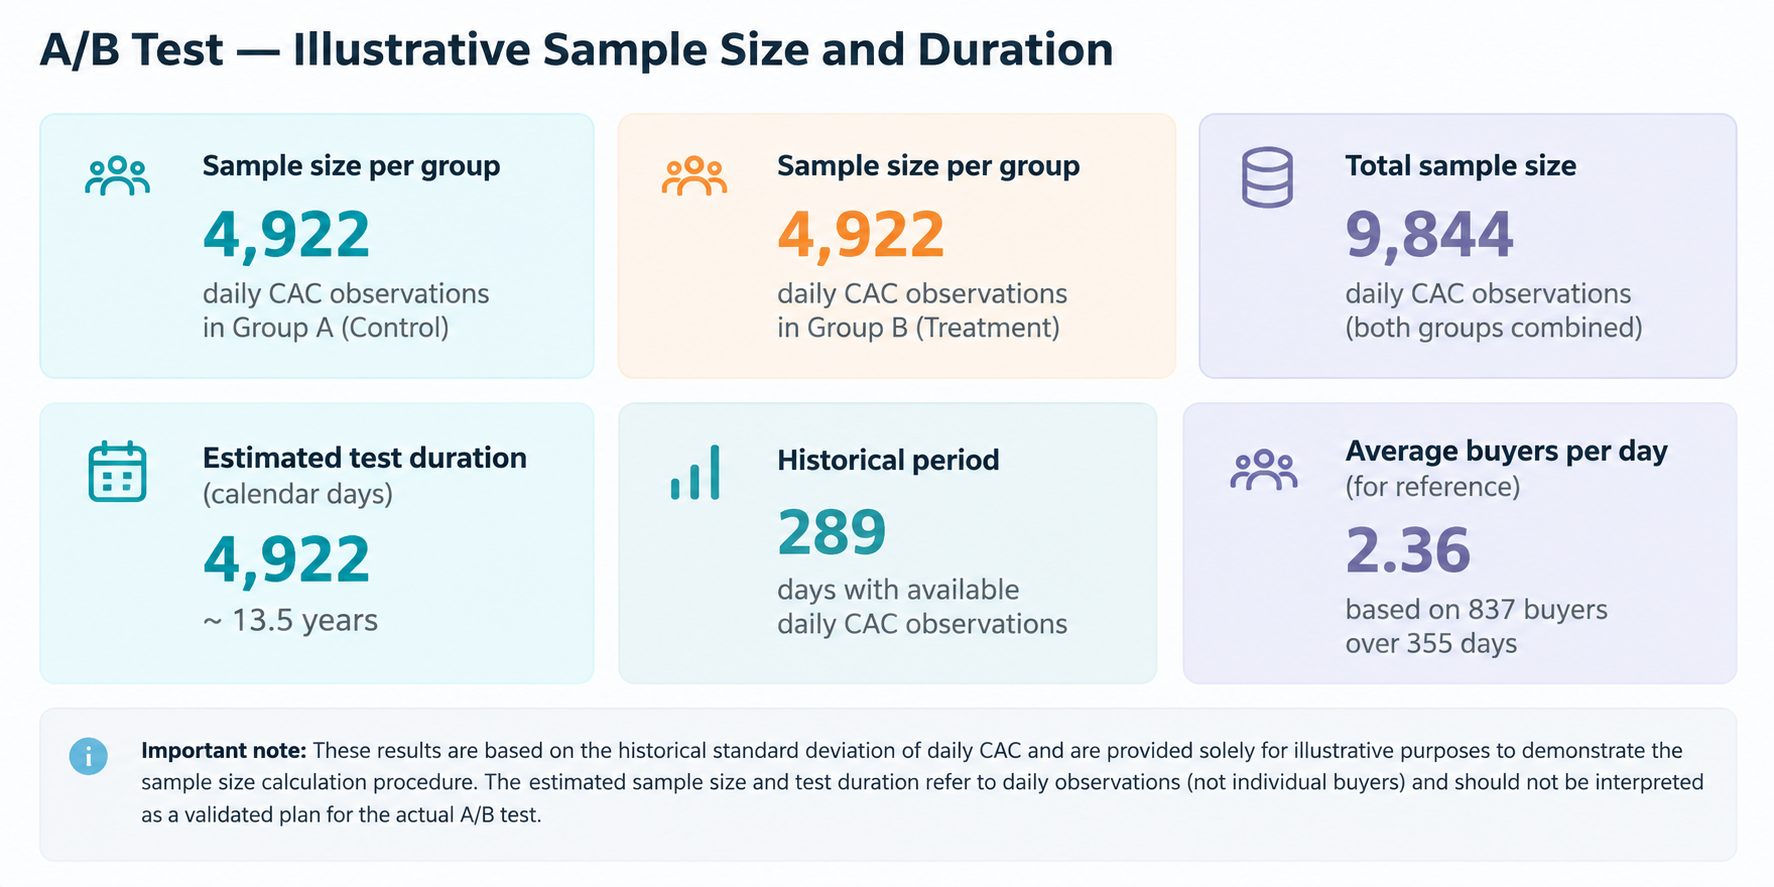

# 4. Metric Tree



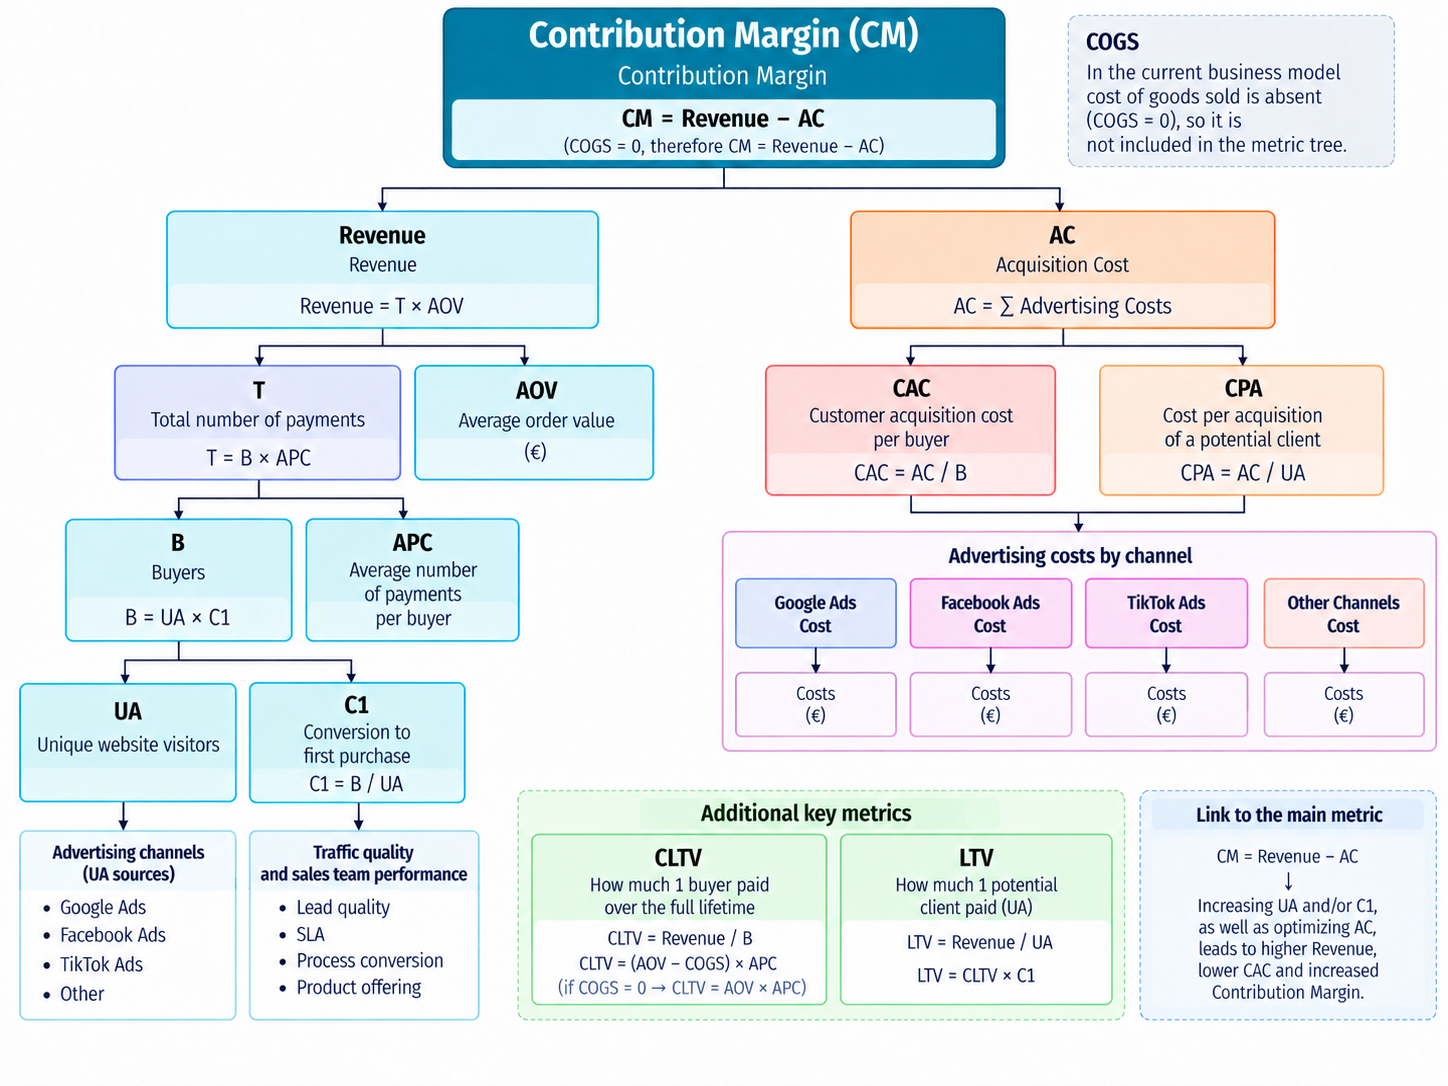